# Open Brewery DB: data preparation and first exploratory comparison

This is the first notebook of the project. It takes the Open Brewery DB snapshot, checks its quality, handles duplicate records and builds the two datasets that the later notebooks and the dashboard read:

- `analysis_all_records`: every record with coordinates, after removing exact duplicates (9488 records).
- `analysis_unique_records`: the same records, with a brewery that appears twice at the same location counted once (9487 records).

We then compare the two datasets (and in places the raw snapshot) on structure, missing values, unique values, brewery types, countries, states, cities, coordinate coverage, concentration and the latitude/longitude distribution. Near the end we go back to the raw records that have no coordinates and check `state` against `state_province`.

**Reading notes**
- The notebook grew while we worked. The stored outputs come from more than one kernel session, so the execution counts are not in order, and the API cell was not run in the stored session (the data was loaded from the saved SQLite files).
- Some cells are scratch checks: spot checks by position, repeated cells, commented-out code. We left them in and flag them where they could mislead.
- Coordinates here are the uncorrected source values. A few records have latitude and longitude swapped; we found them later and the dashboard corrects them through `data/coordinate_corrections.csv`.
- The dashboard now carries this work: the Overview and Pipeline & Quality tabs in `app.py`, `pages/1_Data_Quality.py`, `pages/6_Brewery_Types.py`, `pages/7_Countries_States_Cities.py` and `pages/3_Lat_Lon_Distribution.py`.

## Project plan

The first two cells are the plan we wrote at the start: the dashboard milestones and the analysis pipeline. They hold comments only. This notebook covers the pipeline up to the exploratory analysis; the geographic analysis and the clustering continue in `brewery_geographic_analysis.ipynb` and `brewery_clustering_all_runs.ipynb`.

In [1]:
# Milestone 1 — Overview and filters
# Dataset toggle, KPIs, brewery-type distribution, top states and missing-data indicators.
#
#
#
# Milestone 2 — Geographic exploration
# Interactive point maps, country/state/city filters, and brewery details on hover.
#
#
#
# Milestone 3 — Dispersion and outliers
# Reuse your existing results for median distance, IQR, P90, state rankings and IQR-based outlier flags.
#
#
#
# Milestone 4 — DBSCAN versus HDBSCAN
# Compare cluster counts, noise percentage, cluster sizes and geographic patterns for the parameter combinations you evaluated.
#
#
#
# Milestone 5 — Portfolio deployment
# Add a README, methodology notes, screenshots and deployment instructions. Choose hosting after checking current availability and limitations for your location.

In [2]:
# 1. Data Acquisition
#         ↓
# 2. Database Storage
#         ↓
# 3. Data Quality & Validation
#         ↓
# 4. Duplicate / Record Identity Analysis
#         ↓
# 5. Define Analysis Datasets
#         ↓
#    ┌──────────────────────────┐
#    │ all records              │
#    │ unique locations         │
#    └──────────────────────────┘
#         ↓
# 6. Exploratory Data Analysis
#         │
#         ├── Dataset composition
#         ├── Brewery types
#         ├── Country distribution
#         ├── Region distribution
#         ├── City distribution
#         ├── City concentration
#         └── All-record vs unique-location comparison
#         ↓
# 7. Geographic Analysis
#         │
#         ├── Coordinate coverage
#         ├── Geographic centers
#         ├── Distance from center
#         ├── Spatial dispersion
#         └── Geographic outliers
#         ↓
# 8. Spatial Clustering
#         │
#         ├── k-distance analysis
#         ├── DBSCAN parameter selection
#         ├── Cluster size
#         ├── Cluster share
#         ├── Noise
#         └── All-record vs unique-location sensitivity
#         ↓
# 9. SQL Analysis
#         │
#         ├── Counts
#         ├── rankings
#         ├── concentration
#         └── duplicate/location comparisons
#         ↓
# 10. Visualization
#         │
#         ├── distributions
#         ├── concentration
#         ├── geographic maps
#         └── DBSCAN clusters
#         ↓
# 11. Insights & Conclusions

## 1. Data acquisition and storage

We pull every brewery from the Open Brewery DB API page by page and store the snapshot in `data/raw_breweries.db`, so the analysis does not depend on the live API and can be repeated on the same data.

In the stored run the API cell was not executed. The cell after it loads the saved snapshot and the two analysis databases (written in section 7) instead, which is why the DataFrame conversion that follows fails with a `NameError`: `raw_breweries_df` already exists from the database. The path checks print a Windows path from the machine where the notebook first ran.

In [1]:
# Purpose: Imports the libraries used for API requests, DataFrame manipulation, and numerical operations.

import requests
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)


In [ ]:
# Purpose: Fetches all brewery records from Open Brewery DB page by page (200 records per request) and stores the API results in a list.

# Not run in the stored session: the next cell loads the saved snapshot instead.
api_url = 'https://api.openbrewerydb.org/v1/breweries'

brewery_records = []

page_number = 1

while True:

    request_params = {
        'per_page' : 200,
        'page' : page_number
    }

    api_response = requests.get(api_url, params=request_params)
    page_data = api_response.json()

    if len(page_data) == 0:
        break

    brewery_records.extend(page_data)

    page_number += 1


In [2]:
# Load the saved snapshot and the two analysis datasets. All three files are written by this
# notebook (sections 1 and 7), so the rest of the notebook can run without calling the API.
# Purpose: Contains notes/comments describing the section or intended code.

import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("sqlite:///data/analysis_all_records.db")

analysis_all_records = pd.read_sql(
    "SELECT * FROM analysis_all_records",
    con=engine
)

analysis_all_records.info()
# Purpose: Contains notes/comments describing the section or intended code.

import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("sqlite:///data/analysis_unique_records.db")

analysis_unique_records = pd.read_sql(
    "SELECT * FROM analysis_unique_records",
    con=engine
)

analysis_unique_records.info()


import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("sqlite:///data/raw_breweries.db")

raw_breweries_df = pd.read_sql(
    "SELECT * FROM raw_breweries",
    con=engine
)

raw_breweries_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9488 entries, 0 to 9487
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              9488 non-null   str    
 1   name            9488 non-null   str    
 2   brewery_type    9488 non-null   str    
 3   address_1       9340 non-null   str    
 4   address_2       322 non-null    str    
 5   address_3       38 non-null     str    
 6   city            9488 non-null   str    
 7   state_province  9488 non-null   str    
 8   postal_code     9487 non-null   str    
 9   country         9488 non-null   str    
 10  longitude       9488 non-null   float64
 11  latitude        9488 non-null   float64
 12  phone           8565 non-null   str    
 13  website_url     8631 non-null   str    
 14  state           9488 non-null   str    
 15  street          9340 non-null   str    
dtypes: float64(2), str(14)
memory usage: 2.8 MB
<class 'pandas.DataFrame'>
RangeIndex: 9487 e

In [3]:
# Purpose: Converts the list of brewery dictionaries returned by the API into a pandas DataFrame.

# Needs brewery_records from the API cell. In the stored run that cell was skipped, hence the
# NameError; raw_breweries_df already holds the snapshot loaded from the database.
raw_breweries_df = pd.DataFrame(brewery_records)

NameError: name 'brewery_records' is not defined

In [3]:
# Purpose: Checks the number of rows and columns in the brewery DataFrame.

raw_breweries_df.shape

(11959, 16)

In [7]:
# Purpose: Imports Python's `inspect` module so function signatures can be inspected.

import inspect

In [8]:
#   @: Creates a SQLite SQLAlchemy database_engine and writes the brewery DataFrame to the `breweries` table, replacing an existing table.

# Writes the snapshot to the `raw_breweries` table of data/raw_breweries.db.
from sqlalchemy import create_engine

database_engine = create_engine('sqlite:///data/raw_breweries.db')

raw_breweries_df.to_sql(
    'raw_breweries',
    con = database_engine,
    if_exists = 'replace',
    index = False
)

11959

In [9]:
#   @: Checks the notebook's current working directory and lists the files and folders available there.

from pathlib import Path
import pandas as pd
from sqlalchemy import create_engine, inspect

# Check the current working directory
base_dir = Path.cwd()

print("Current working directory:", base_dir)
print("Files and folders:")
print(list(base_dir.iterdir()))

Current working directory: D:\Tutorials\data science\Data Science IBM\Applied Data Science Capstone\project
Files and folders:
[WindowsPath('D:/Tutorials/data science/Data Science IBM/Applied Data Science Capstone/project/.git'), WindowsPath('D:/Tutorials/data science/Data Science IBM/Applied Data Science Capstone/project/.gitignore'), WindowsPath('D:/Tutorials/data science/Data Science IBM/Applied Data Science Capstone/project/.idea'), WindowsPath('D:/Tutorials/data science/Data Science IBM/Applied Data Science Capstone/project/additional.ipynb'), WindowsPath('D:/Tutorials/data science/Data Science IBM/Applied Data Science Capstone/project/all_brewery.ipynb'), WindowsPath('D:/Tutorials/data science/Data Science IBM/Applied Data Science Capstone/project/app.py'), WindowsPath('D:/Tutorials/data science/Data Science IBM/Applied Data Science Capstone/project/breweries.ipynb'), WindowsPath('D:/Tutorials/data science/Data Science IBM/Applied Data Science Capstone/project/brewery.ipynb'), Wi

In [10]:
#   @: Builds the expected SQLite database path and checks whether the database file exists.

db_path = base_dir / "data" / "raw_breweries.db"

print("Database exists:", db_path.exists())
print("Database path:", db_path)

Database exists: True
Database path: D:\Tutorials\data science\Data Science IBM\Applied Data Science Capstone\project\data\raw_breweries.db


In [11]:
print("db_path:", db_path)
print("absolute path:", db_path.resolve())
print("exists:", db_path.exists())
print("parent exists:", db_path.parent.exists())

db_path: D:\Tutorials\data science\Data Science IBM\Applied Data Science Capstone\project\data\raw_breweries.db
absolute path: D:\Tutorials\data science\Data Science IBM\Applied Data Science Capstone\project\data\raw_breweries.db
exists: True
parent exists: True


In [12]:
#   @: Inspects the SQLite database and lists its tables.

database_engine = create_engine(
    f"sqlite:///{db_path.as_posix()}"
)

# List all tables in the database
db_inspector = inspect(database_engine)

print("Tables:", db_inspector.get_table_names())

Tables: ['raw_breweries']


## 2. First look at the raw snapshot

The snapshot has 11959 records and 16 columns. `id`, `name`, `brewery_type`, `city`, `state_province`, `country` and `state` are always filled. The gaps are in `address_3` (11919 missing) and `address_2` (11628), which few breweries use, in latitude and longitude (2468 each), `phone` (1393), `website_url` (1337), `address_1` and `street` (754 each) and `postal_code` (2). Two columns are copies of others: `street` repeats `address_1`, and `state` repeats `state_province` (checked in section 10).

In [4]:
# Purpose: Displays DataFrame structure, column names, non-null counts, page_data types, and memory usage.

raw_breweries_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11959 entries, 0 to 11958
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              11959 non-null  str    
 1   name            11959 non-null  str    
 2   brewery_type    11959 non-null  str    
 3   address_1       11205 non-null  str    
 4   address_2       331 non-null    str    
 5   address_3       40 non-null     str    
 6   city            11959 non-null  str    
 7   state_province  11959 non-null  str    
 8   postal_code     11957 non-null  str    
 9   country         11959 non-null  str    
 10  longitude       9491 non-null   float64
 11  latitude        9491 non-null   float64
 12  phone           10566 non-null  str    
 13  website_url     10622 non-null  str    
 14  state           11959 non-null  str    
 15  street          11205 non-null  str    
dtypes: float64(2), str(14)
memory usage: 3.5 MB


In [5]:
# Purpose: Displays the first five brewery records to inspect the dataset contents.



raw_breweries_df.head()

,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street
0,ae7b3174-8be8-4d53-a3a5-9b8240970eea,'s,brewpub,Friesener Straße 1,NaN,NaN,Kronach,Bayern,96317,Germany,11.327765,50.241246,+49 9261 628000,http://www.antla.de,Bayern,Friesener Straße 1
1,aa7cbe9b-3a0f-4888-9884-6186b0042b55,’t Drankorgel,micro,31a Geelsebaan,NaN,NaN,Mol,Vlaanderen,2400,Belgium,5.056955,51.176258,+32 496 76 40 63,http://tdrankorgel.be/,Vlaanderen,31a Geelsebaan
2,1034754f-abf9-4b42-bd6d-37e110ba4b1a,'T Kroontje,micro,62 Hogebrug,NaN,NaN,Lebbeke,Vlaanderen,9280,Belgium,4.091393,51.007888,+32 495 43 33 25,http://www.tkroontje.be/,Vlaanderen,62 Hogebrug
3,5128df48-79fc-4f0f-8b52-d06be54d0cec,(405) Brewing Co,micro,1716 Topeka St,NaN,NaN,Norman,Oklahoma,73069-8224,United States,-97.468182,35.257389,4058160490,http://www.405brewing.com,Oklahoma,1716 Topeka St
4,9c5a66c8-cc13-416f-a5d9-0a769c87d318,(512) Brewing Co,micro,407 Radam Ln Ste F200,NaN,NaN,Austin,Texas,78745-1197,United States,NaN,NaN,5129211545,http://www.512brewing.com,Texas,407 Radam Ln Ste F200


In [6]:
# Purpose: Counts missing values in every column.

raw_breweries_df.isnull().sum()

id                    0
name                  0
brewery_type          0
address_1           754
address_2         11628
address_3         11919
city                  0
state_province        0
postal_code           2
country               0
longitude          2468
latitude           2468
phone              1393
website_url        1337
state                 0
street              754
dtype: int64

In [7]:
# Purpose: Lists all DataFrame column names.

raw_breweries_df.columns



Index(['id', 'name', 'brewery_type', 'address_1', 'address_2', 'address_3',
       'city', 'state_province', 'postal_code', 'country', 'longitude',
       'latitude', 'phone', 'website_url', 'state', 'street'],
      dtype='str')

### Coordinate checks

No latitude or longitude lies outside the valid range. Latitude and longitude are always missing together: 2468 records have neither, none has only one, and 9491 have both. A valid range does not prove a correct position, though: a few records with swapped latitude and longitude pass this check (see section 8). The short cells that follow are quick arithmetic checks on these counts.

In [8]:
# Purpose: Identifies records with invalid or out-of-range latitude/longitude values.

# ==========================================
# 2. COORDINATE VALIDATION
# ==========================================

invalid_coordinate_records = raw_breweries_df[
    (
        raw_breweries_df['latitude'].notna()
        & ~raw_breweries_df['latitude'].between(-90, 90)
    )
    |
    (
        raw_breweries_df['longitude'].notna()
        & ~raw_breweries_df['longitude'].between(-180, 180)
    )
].copy()

print("Invalid coordinate rows:", len(invalid_coordinate_records))

invalid_coordinate_records[
    ['id', 'name', 'country', 'state_province',
     'city', 'latitude', 'longitude']
]

Invalid coordinate rows: 0


,id,name,country,state_province,city,latitude,longitude


In [9]:
raw_breweries_df.shape

(11959, 16)

In [10]:
# Purpose: Identifies records with invalid or out-of-range latitude/longitude values.

invalid_coordinate_records

,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street


In [11]:
# Purpose: Builds a column-by-column summary of missing values.

missing_values_summary = pd.DataFrame({
    'missing_count': raw_breweries_df.isna().sum(),
    'missing_percentage': raw_breweries_df.isna().mean()
}).sort_values('missing_percentage', ascending = False)

display(missing_values_summary.round(2))

,missing_count,missing_percentage
address_3,11919,1.00
address_2,11628,0.97
longitude,2468,0.21
latitude,2468,0.21
phone,1393,0.12
website_url,1337,0.11
address_1,754,0.06
street,754,0.06
postal_code,2,0.00
state_province,0,0.00


In [12]:
# Purpose: Creates boolean masks identifying records with missing latitude or longitude values.

latitude_missing = raw_breweries_df['latitude'].isna()
longitude_missing = raw_breweries_df['longitude'].isna()

both_coordinates_missing_indices = raw_breweries_df.index[latitude_missing & longitude_missing].tolist()
latitude_only_missing_indices = raw_breweries_df.index[latitude_missing & ~longitude_missing].tolist()
longitude_only_missing_indices = raw_breweries_df.index[longitude_missing & ~latitude_missing].tolist()
both_coordinates_available_indices = raw_breweries_df.index[~latitude_missing & ~longitude_missing].tolist()

print("Both coordinates missing:", len(both_coordinates_missing_indices))
print("Latitude missing only:", len(latitude_only_missing_indices))
print("Longitude missing only:", len(longitude_only_missing_indices))
print("Both coordinates available:", len(both_coordinates_available_indices))

Both coordinates missing: 2468
Latitude missing only: 0
Longitude missing only: 0
Both coordinates available: 9491


In [13]:
raw_breweries_df.isna().sum()

id                    0
name                  0
brewery_type          0
address_1           754
address_2         11628
address_3         11919
city                  0
state_province        0
postal_code           2
country               0
longitude          2468
latitude           2468
phone              1393
website_url        1337
state                 0
street              754
dtype: int64

In [14]:
latitude_missing.sum()

np.int64(2468)

In [15]:
# Records not in analysis_all_records: 2468 without coordinates plus 3 exact duplicates (section 3).
11959 - 9488

2471

In [16]:
# Raw records with both coordinates.
11959 - 2468

9491

In [17]:
longitude_missing.sum()

np.int64(2468)

In [18]:
# Careful: `~` applies a bitwise NOT to the count, so this is not the number of present
# coordinates (that is 9491, see above).
~longitude_missing.sum()

np.int64(-2469)

In [19]:
# Purpose: Identifies records with invalid or out-of-range latitude/longitude values.

# Identify coordinates outside valid global ranges
invalid_latitude_mask = (
    raw_breweries_df["latitude"].notna()
    & ~raw_breweries_df["latitude"].between(-90, 90)
)

invalid_longitude_mask = (
    raw_breweries_df["longitude"].notna()
    & ~raw_breweries_df["longitude"].between(-180, 180)
)

print("Invalid latitude:", invalid_latitude_mask.sum())
print("Invalid longitude:", invalid_longitude_mask.sum())

invalid_coordinate_records = raw_breweries_df.loc[
    invalid_latitude_mask | invalid_longitude_mask,
    ["id", "name", "country", "state_province",
     "latitude", "longitude"]
]

display(invalid_coordinate_records)

Invalid latitude: 0
Invalid longitude: 0


,id,name,country,state_province,latitude,longitude


## 3. Duplicates and record identity

No two records share an `id`, so duplicates have to be found on the other fields. We group the records on several sets of columns and keep the groups with more than one record. With name, place, type, website and coordinates as the key, four groups appear (one of them, Peoria Artisan Brewery, has no coordinates). With all columns except `id`, three remain.

In [20]:
# Purpose: Counts duplicate brewery IDs to detect exact identifier duplication.

print("Duplicate IDs:", raw_breweries_df["id"].duplicated().sum())

duplicate_id_records = raw_breweries_df[
    raw_breweries_df["id"].duplicated(keep=False)
].sort_values("id")

display(duplicate_id_records)

Duplicate IDs: 0


,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street


In [21]:
help(raw_breweries_df.duplicated)

Help on method duplicated in module pandas.core.frame:

duplicated(subset: 'Hashable | Iterable[Hashable] | None' = None, keep: 'DropKeep' = 'first') -> 'Series' method of pandas.DataFrame instance
    Return boolean Series denoting duplicate rows.

    Considering certain columns is optional.

    Parameters
    ----------
    subset : column label or iterable of labels, optional
        Only consider certain columns for identifying duplicates, by
        default use all of the columns.
    keep : {'first', 'last', False}, default 'first'
        Determines which duplicates (if any) to mark.

        - ``first`` : Mark duplicates as ``True`` except for the first occurrence.
        - ``last`` : Mark duplicates as ``True`` except for the last occurrence.
        - False : Mark all duplicates as ``True``.

    Returns
    -------
    Series
        Boolean series for each duplicated rows.

    See Also
    --------
    Index.duplicated : Equivalent method on index.
    Series.duplicated

In [22]:
# Purpose: Groups brewery records by selected attributes to investigate possible duplicates.

# dropna=False keeps missing values as group keys, so records missing the same fields still group together.
duplicate_name_groups = (
    raw_breweries_df.groupby(
        ["name", "city", "state_province", "country", "brewery_type", "website_url", "latitude", "longitude"],
        dropna=False
    )
    .size()
    .reset_index(name="record_count")
    .query("record_count > 1")
    .sort_values("record_count", ascending=False)
)

duplicate_name_groups

,name,city,state_province,country,brewery_type,website_url,latitude,longitude,record_count
4402,Garage Project,Wellington,Wellington Region,New Zealand,micro,https://garageproject.co.nz/pages/wild-workshop-cellar-door,-41.294183,174.777348,2
8169,Peoria Artisan Brewery,Peoria,Arizona,United States,brewpub,http://www.peoriaartisanbrewing.com,NaN,NaN,2
8342,Pooles Island Brewing Company,Middle River,Maryland,United States,micro,https://www.poolesbrewing.com/,39.352561,-76.400825,2
9248,Scheldebrouwerij,Hoogstraten,Vlaanderen,Belgium,micro,https://www.scheldebrouwerij.com/,51.473112,4.723010,2


In [23]:
# Purpose: Groups brewery records by selected attributes to investigate possible duplicates.

duplicate_groups_by_contact = (
    raw_breweries_df.groupby(
        ["name", "city", "state_province", "country", "address_1", "postal_code", "latitude","longitude", "phone", "website_url", "street"],
        dropna=False
    )
    .size()
    .reset_index(name="record_count")
    .query("record_count > 1")
    .sort_values("record_count", ascending=False)
)

duplicate_groups_by_contact

,name,city,state_province,country,address_1,postal_code,latitude,longitude,phone,website_url,street,record_count
4402,Garage Project,Wellington,Wellington Region,New Zealand,7 Furness Lane,6011,-41.294183,174.777348,+64 21 245 3300,https://garageproject.co.nz/pages/wild-workshop-cellar-door,7 Furness Lane,2
8343,Pooles Island Brewing Company,Middle River,Maryland,United States,11695 Crossroads Circle,21220,39.352561,-76.400825,4106309164,https://www.poolesbrewing.com/,11695 Crossroads Circle,2
9249,Scheldebrouwerij,Hoogstraten,Vlaanderen,Belgium,5 Wenenstraat,2321,51.473112,4.723010,+32 3 665 36 96,https://www.scheldebrouwerij.com/,5 Wenenstraat,2


In [24]:
# Purpose: Groups brewery records by selected attributes to investigate possible duplicates.

duplicate_records = (
    raw_breweries_df.groupby(
        ["name", "brewery_type", "address_1", "address_2", "address_3", "city", "state_province", "postal_code", "country", "latitude", "longitude", "phone", "website_url", "state", "street"],
        dropna=False
    )
    .size()
    .reset_index(name="record_count")
    .query("record_count > 1")
    .sort_values("record_count", ascending=False)
)

duplicate_records

,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,latitude,longitude,phone,website_url,state,street,record_count
4402,Garage Project,micro,7 Furness Lane,NaN,NaN,Wellington,Wellington Region,6011,New Zealand,-41.294183,174.777348,+64 21 245 3300,https://garageproject.co.nz/pages/wild-workshop-cellar-door,Wellington Region,7 Furness Lane,2
8343,Pooles Island Brewing Company,micro,11695 Crossroads Circle,NaN,NaN,Middle River,Maryland,21220,United States,39.352561,-76.400825,4106309164,https://www.poolesbrewing.com/,Maryland,11695 Crossroads Circle,2
9249,Scheldebrouwerij,micro,5 Wenenstraat,NaN,NaN,Hoogstraten,Vlaanderen,2321,Belgium,51.473112,4.723010,+32 3 665 36 96,https://www.scheldebrouwerij.com/,Vlaanderen,5 Wenenstraat,2


In [25]:
# Note: 4402, 8343 and 9249 are row labels of the grouped tables above, not of raw_breweries_df,
# so this prints unrelated breweries. The next cell finds the real rows.
print(raw_breweries_df.loc[[4402, 4403, 8343, 8344, 9249, 9250]])

                                        id                              name  \
4402  a99904b4-3a41-46ef-b135-68f280543432         GameCraft Brewing Anaheim   
4403  62126ec0-49a3-458f-9f0c-b21a3679a491            Gamla Enskede Bryggeri   
8343  cdf91a93-80df-4940-af33-6a5562b7eef8              Point Breeze Brewing   
8344  d454edbb-ddb4-4aaa-a922-e6c7ad84c73b            Point Labaddie Brewery   
9249  f4dfd9ef-1936-4d1a-b0b5-9358543a3ede  Scarlet Lane Brewing Company LLC   
9250  b90da363-96c4-444d-9f13-d984aac108fd                         Scassenes   

     brewery_type              address_1 address_2 address_3          city  \
4402        micro   1884 S Santa Cruz St       NaN       NaN       Anaheim   
4403        micro         Bolidenvägen 8       NaN       NaN   Johanneshov   
8343        micro         1225 S 28th St       NaN       NaN  Philadelphia   
8344        micro        1029 Thiebes Rd       NaN       NaN       Labadie   
9249        micro          7724 Depot St       Na

### Exact duplicates

Three pairs are identical in every column except `id`: Garage Project (Wellington), Pooles Island Brewing Company (Middle River, Maryland) and Scheldebrouwerij (Hoogstraten). Each is one brewery entered twice, so we keep the first record of each pair. The two identical cells that follow confirm it: across the six rows `id` takes 6 values and the other columns at most 3, one per pair.

In [26]:
# Mark every record that repeats all columns except id (keep=False marks both records of a pair).
duplicate_record_columns = [
    "name", "brewery_type", "address_1", "address_2", "address_3",
    "city", "state_province", "postal_code", "country",
    "latitude", "longitude", "phone", "website_url",
    "state", "street"
]

duplicate_record_mask = raw_breweries_df.duplicated(
    subset=duplicate_record_columns,
    keep=False
)

duplicate_record_indices = raw_breweries_df.index[duplicate_record_mask].tolist()

print(duplicate_record_indices)

[4413, 4414, 8361, 8362, 9260, 9261]


In [27]:
raw_breweries_df.iloc[[4413, 4414, 8361, 8362, 9260, 9261]]

,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street
4413,567b5f41-b403-4098-8ce0-144b4b715660,Garage Project,micro,7 Furness Lane,NaN,NaN,Wellington,Wellington Region,6011,New Zealand,174.777348,-41.294183,+64 21 245 3300,https://garageproject.co.nz/pages/wild-workshop-cellar-door,Wellington Region,7 Furness Lane
4414,67e69496-c58d-49cf-8d4c-ecbc0480cdb9,Garage Project,micro,7 Furness Lane,NaN,NaN,Wellington,Wellington Region,6011,New Zealand,174.777348,-41.294183,+64 21 245 3300,https://garageproject.co.nz/pages/wild-workshop-cellar-door,Wellington Region,7 Furness Lane
8361,8342cc4f-2867-423c-be9c-5384b7e8a3f7,Pooles Island Brewing Company,micro,11695 Crossroads Circle,NaN,NaN,Middle River,Maryland,21220,United States,-76.400825,39.352561,4106309164,https://www.poolesbrewing.com/,Maryland,11695 Crossroads Circle
8362,e9e12c70-825e-404b-b265-dbeb4bdbd556,Pooles Island Brewing Company,micro,11695 Crossroads Circle,NaN,NaN,Middle River,Maryland,21220,United States,-76.400825,39.352561,4106309164,https://www.poolesbrewing.com/,Maryland,11695 Crossroads Circle
9260,33a34b9f-c075-4ec3-9379-6280a9ab281e,Scheldebrouwerij,micro,5 Wenenstraat,NaN,NaN,Hoogstraten,Vlaanderen,2321,Belgium,4.723010,51.473112,+32 3 665 36 96,https://www.scheldebrouwerij.com/,Vlaanderen,5 Wenenstraat
9261,85823946-3b97-468a-adaf-4fd69b11c043,Scheldebrouwerij,micro,5 Wenenstraat,NaN,NaN,Hoogstraten,Vlaanderen,2321,Belgium,4.723010,51.473112,+32 3 665 36 96,https://www.scheldebrouwerij.com/,Vlaanderen,5 Wenenstraat


In [28]:
selected_indices = duplicate_record_indices
raw_breweries_df.iloc[selected_indices]

,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street
4413,567b5f41-b403-4098-8ce0-144b4b715660,Garage Project,micro,7 Furness Lane,NaN,NaN,Wellington,Wellington Region,6011,New Zealand,174.777348,-41.294183,+64 21 245 3300,https://garageproject.co.nz/pages/wild-workshop-cellar-door,Wellington Region,7 Furness Lane
4414,67e69496-c58d-49cf-8d4c-ecbc0480cdb9,Garage Project,micro,7 Furness Lane,NaN,NaN,Wellington,Wellington Region,6011,New Zealand,174.777348,-41.294183,+64 21 245 3300,https://garageproject.co.nz/pages/wild-workshop-cellar-door,Wellington Region,7 Furness Lane
8361,8342cc4f-2867-423c-be9c-5384b7e8a3f7,Pooles Island Brewing Company,micro,11695 Crossroads Circle,NaN,NaN,Middle River,Maryland,21220,United States,-76.400825,39.352561,4106309164,https://www.poolesbrewing.com/,Maryland,11695 Crossroads Circle
8362,e9e12c70-825e-404b-b265-dbeb4bdbd556,Pooles Island Brewing Company,micro,11695 Crossroads Circle,NaN,NaN,Middle River,Maryland,21220,United States,-76.400825,39.352561,4106309164,https://www.poolesbrewing.com/,Maryland,11695 Crossroads Circle
9260,33a34b9f-c075-4ec3-9379-6280a9ab281e,Scheldebrouwerij,micro,5 Wenenstraat,NaN,NaN,Hoogstraten,Vlaanderen,2321,Belgium,4.723010,51.473112,+32 3 665 36 96,https://www.scheldebrouwerij.com/,Vlaanderen,5 Wenenstraat
9261,85823946-3b97-468a-adaf-4fd69b11c043,Scheldebrouwerij,micro,5 Wenenstraat,NaN,NaN,Hoogstraten,Vlaanderen,2321,Belgium,4.723010,51.473112,+32 3 665 36 96,https://www.scheldebrouwerij.com/,Vlaanderen,5 Wenenstraat


In [29]:
# selected_indices = [4407, 4408, 8347, 8348, 9245, 9246]
# raw_breweries_df.iloc[selected_indices]

In [30]:
# nunique over all six rows: id has 6 values and the other columns at most 3 (one per pair),
# so the two records of each pair differ only in id.
selected_indices = [4413, 4414, 8361, 8362, 9260, 9261]

selected_duplicate_rows = raw_breweries_df.loc[selected_indices]

# Check which columns contain differences
different_column_counts = selected_duplicate_rows.nunique(dropna=False)

print(different_column_counts[different_column_counts > 1])

id                6
name              3
address_1         3
city              3
state_province    3
postal_code       3
country           3
longitude         3
latitude          3
phone             3
website_url       3
state             3
street            3
dtype: int64


In [31]:
# Same check as the cell above (repeated).
selected_indices = [4413, 4414, 8361, 8362, 9260, 9261]

selected_duplicate_rows = raw_breweries_df.loc[selected_indices]

# Check which columns contain differences
different_column_counts = selected_duplicate_rows.nunique(dropna=False)

print(different_column_counts[different_column_counts > 1])

id                6
name              3
address_1         3
city              3
state_province    3
postal_code       3
country           3
longitude         3
latitude          3
phone             3
website_url       3
state             3
street            3
dtype: int64


### Building the analysis dataset

We drop the three exact duplicates (keeping the first record of each pair) and then the records without coordinates. The geographic work needs a position, and we do not impute missing ones. That leaves 9488 records. The remaining gaps are mostly in `address_2`/`address_3`, `phone` (923) and `website_url` (857).

In [32]:
# Store all duplicate records separately
selected_duplicate_indices = [4413, 4414, 8361, 8362, 9260, 9261]

duplicated_records_df = raw_breweries_df.loc[selected_duplicate_indices].copy()

# Remove duplicate records from the analysis dataset,
# keeping the first record from each duplicate pair
analysis_df = raw_breweries_df.drop_duplicates(
    subset=duplicate_record_columns,
    keep="first"
).copy()

In [33]:
# Keep only records with both coordinates: we exclude records without a position rather than impute one.
analysis_df = analysis_df.dropna(
    subset=["latitude", "longitude"]
).copy()

In [34]:
analysis_df.shape

(9488, 16)

In [35]:
# Purpose: Builds a column-by-column summary of missing values.

missing_values_summary = pd.DataFrame({
    'missing_count': analysis_df.isna().sum(),
    'missing_percentage': analysis_df.isna().mean()
}).sort_values('missing_percentage', ascending = False)

print(missing_values_summary.round(2))

                missing_count  missing_percentage
address_3                9450                1.00
address_2                9166                0.97
phone                     923                0.10
website_url               857                0.09
address_1                 148                0.02
street                    148                0.02
postal_code                 1                0.00
id                          0                0.00
state_province              0                0.00
city                        0                0.00
name                        0                0.00
brewery_type                0                0.00
latitude                    0                0.00
longitude                   0                0.00
country                     0                0.00
state                       0                0.00


### Same brewery, different coordinates

Next we leave `id` and the coordinates out of the key, to find records that agree on every descriptive field but may sit at different points. Six pairs appear, all in Belgium: Belle-Vue, Caulier, Deca Services, Lefebvre, Liefmans and Timmermans. We measure how far apart they are further down.

In [36]:
# Identity key without id and coordinates: finds records that agree on every descriptive field
# but may sit at different points.
duplicate_keys = ["name", "brewery_type", "address_1", "address_2", "address_3", "city", "state_province", "postal_code", "country", "phone", "website_url", "state", "street"]

In [37]:
analysis_df.columns

Index(['id', 'name', 'brewery_type', 'address_1', 'address_2', 'address_3',
       'city', 'state_province', 'postal_code', 'country', 'longitude',
       'latitude', 'phone', 'website_url', 'state', 'street'],
      dtype='str')

In [38]:
analysis_df.shape

(9488, 16)

In [39]:
# Purpose: Compares coordinates among duplicate brewery records to determine whether locations agree.

# One row per identity group: how many records, ids and distinct coordinate pairs it holds.
coordinate_comparison = (
    analysis_df
    .groupby(duplicate_keys, dropna=False)
    .apply(
        lambda group: pd.Series({
            "record_count": len(group),
            "unique_ids": group["id"].nunique(),
            "unique_coordinate_pairs": (
                group[["latitude", "longitude"]]
                .drop_duplicates()
                .shape[0]
            ),
            "missing_coordinate_rows": (
                group[["longitude", "latitude"]]
                .isna()
                .any(axis=1)
                .sum()
            )
        }),
        include_groups=False
    )
    .reset_index()
)

coordinate_comparison

,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,phone,website_url,state,street,record_count,unique_ids,unique_coordinate_pairs,missing_coordinate_rows
0,'T Kroontje,micro,62 Hogebrug,NaN,NaN,Lebbeke,Vlaanderen,9280,Belgium,+32 495 43 33 25,http://www.tkroontje.be/,Vlaanderen,62 Hogebrug,1,1,1,0
1,'s,brewpub,Friesener Straße 1,NaN,NaN,Kronach,Bayern,96317,Germany,+49 9261 628000,http://www.antla.de,Bayern,Friesener Straße 1,1,1,1,0
2,(405) Brewing Co,micro,1716 Topeka St,NaN,NaN,Norman,Oklahoma,73069-8224,United States,4058160490,http://www.405brewing.com,Oklahoma,1716 Topeka St,1,1,1,0
3,1 of Us Brewing Company,micro,8100 Washington Ave,NaN,NaN,Mount Pleasant,Wisconsin,53406-3920,United States,2624847553,https://www.1ofusbrewing.com,Wisconsin,8100 Washington Ave,1,1,1,0
4,1. Altenberger Brauhaus,brewpub,Zirndorfer Straße 18,NaN,NaN,Oberasbach,Bayern,90522,Germany,+49 911 604237,http://www.altenberger-brauhaus.de,Bayern,Zirndorfer Straße 18,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9477,플레이그라운드 브루어리(playground Brewery),brewpub,"246-13, Isanpo-gil",Ilsanseo-gu,NaN,Goyang-si,Gyeonggido,10203,South Korea,031-912-2463,https://www.playgroundbrewery.com/,Gyeonggido,"246-13, Isanpo-gil",1,1,1,0
9478,핸드앤몰트 (Hand and Malt),brewpub,"19, Hangang-daero 38ga-gil",NaN,NaN,Yongsan-gu,Seoul,04386,South Korea,070-7178-4011,http://handandmalt.com/,Seoul,"19, Hangang-daero 38ga-gil",1,1,1,0
9479,허심청브루잉(Hursimchung Bru),brewpub,"23, Geumganggongwon-ro 20beon-gil",NaN,NaN,Dongnae-gu,Busan,47709,South Korea,051-550-2345,https://www.hotelnongshim.com/kr/index.php?pCode=hbrau_info,Busan,"23, Geumganggongwon-ro 20beon-gil",1,1,1,0
9480,헤이스탁 브루어리(Haystack Brewery),brewpub,"25, Pangyogongwon-ro 3-gil",Bundang-gu,NaN,Seongnam-si,Gyeonggido,13477,South Korea,070-7631-1110,NaN,Gyeonggido,"25, Pangyogongwon-ro 3-gil",1,1,1,0


In [40]:
# Get the duplicate groups where at least 2 records share the same duplicate_keys
duplicate_groups = coordinate_comparison[
    coordinate_comparison["record_count"] >= 2
]

# Get the original records belonging to those groups
duplicate_records_df = analysis_df.merge(
    duplicate_groups[duplicate_keys],
    on=duplicate_keys,
    how="inner"
)

duplicate_records_df

,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street
0,3c9196e9-95d7-4298-a5e0-872a9676fd2a,Belle-Vue,micro,144 Bergensesteenweg,NaN,NaN,Sint-Pieters-Leeuw,Région flamande,1600,Belgium,4.287223,50.798541,NaN,http://www.ab-inbev.com/,Région flamande,144 Bergensesteenweg
1,ae40dc08-d065-4649-970a-08d653b75d91,Belle-Vue,micro,144 Bergensesteenweg,NaN,NaN,Sint-Pieters-Leeuw,Région flamande,1600,Belgium,4.287245,50.799011,NaN,http://www.ab-inbev.com/,Région flamande,144 Bergensesteenweg
2,3d3595e7-2cc7-4e1c-b9e5-1a4d89d08d80,Caulier,micro,134 Rue de Sondeville,NaN,NaN,Péruwelz,Région wallonne,7600,Belgium,3.588747,50.502780,+32 69 36 26 10,http://brasseriecaulier.beer/,Région wallonne,134 Rue de Sondeville
3,9ee2811d-cf6e-4495-89e5-aff7e70a9e25,Caulier,micro,134 Rue de Sondeville,NaN,NaN,Péruwelz,Région wallonne,7600,Belgium,3.587876,50.502688,+32 69 36 26 10,http://brasseriecaulier.beer/,Région wallonne,134 Rue de Sondeville
4,6472bf0d-59bc-44e5-a000-353e3ce5f063,Deca Services,micro,4 Elverdingestraat,NaN,NaN,Vleteren,Vlaanderen,8640,Belgium,2.790461,50.899519,+32 57 42 20 75,http://www.decabrouwerij.be/,Vlaanderen,4 Elverdingestraat
5,f77ec937-f153-448f-b1a6-637beef692fd,Deca Services,micro,4 Elverdingestraat,NaN,NaN,Vleteren,Vlaanderen,8640,Belgium,2.791698,50.899150,+32 57 42 20 75,http://www.decabrouwerij.be/,Vlaanderen,4 Elverdingestraat
6,69d5f173-24d2-473d-af3e-87c57e1276f4,Lefebvre,micro,54 Chemin du Croly,NaN,NaN,Rebecq,Région wallonne,1430,Belgium,4.151326,50.674488,+32 67 67 07 66,http://www.brasserielefebvre.be/,Région wallonne,54 Chemin du Croly
7,f354089f-3ef6-4158-b2c7-96163bf755fa,Lefebvre,micro,54 Chemin du Croly,NaN,NaN,Rebecq,Région wallonne,1430,Belgium,4.152116,50.674771,+32 67 67 07 66,http://www.brasserielefebvre.be/,Région wallonne,54 Chemin du Croly
8,4d61de42-eaeb-488a-b10f-f3727e9176d9,Liefmans,micro,200 Aalststraat,NaN,NaN,Oudenaarde,Vlaanderen,9700,Belgium,4.319382,50.958683,+32 3 866 95 21,https://www.liefmans.com/nl-be/brouwerij,Vlaanderen,200 Aalststraat
9,c85ce64e-0f31-4123-bef5-ca1abc080fc9,Liefmans,micro,200 Aalststraat,NaN,NaN,Oudenaarde,Vlaanderen,9700,Belgium,3.616191,50.846320,+32 3 866 95 21,https://www.liefmans.com/nl-be/brouwerij,Vlaanderen,200 Aalststraat


In [41]:
# Same groups as the cell above, but keeping the original row labels.
# Identify the duplicate groups
duplicate_groups = coordinate_comparison[
    coordinate_comparison["record_count"] >= 2
]

# Create a mask for records belonging to those groups
duplicate_records_mask = (
    analysis_df[duplicate_keys]
    .merge(
        duplicate_groups[duplicate_keys].drop_duplicates(),
        on=duplicate_keys,
        how="left",
        indicator=True
    )["_merge"]
    .eq("both")
)

# Get the original indexes
duplicate_record_indices = analysis_df.index[duplicate_records_mask]

# Put the records into a separate DataFrame
duplicate_records_df = analysis_df.loc[duplicate_record_indices]

duplicate_records_df

,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street
1081,3c9196e9-95d7-4298-a5e0-872a9676fd2a,Belle-Vue,micro,144 Bergensesteenweg,NaN,NaN,Sint-Pieters-Leeuw,Région flamande,1600,Belgium,4.287223,50.798541,NaN,http://www.ab-inbev.com/,Région flamande,144 Bergensesteenweg
1082,ae40dc08-d065-4649-970a-08d653b75d91,Belle-Vue,micro,144 Bergensesteenweg,NaN,NaN,Sint-Pieters-Leeuw,Région flamande,1600,Belgium,4.287245,50.799011,NaN,http://www.ab-inbev.com/,Région flamande,144 Bergensesteenweg
2503,3d3595e7-2cc7-4e1c-b9e5-1a4d89d08d80,Caulier,micro,134 Rue de Sondeville,NaN,NaN,Péruwelz,Région wallonne,7600,Belgium,3.588747,50.502780,+32 69 36 26 10,http://brasseriecaulier.beer/,Région wallonne,134 Rue de Sondeville
2504,9ee2811d-cf6e-4495-89e5-aff7e70a9e25,Caulier,micro,134 Rue de Sondeville,NaN,NaN,Péruwelz,Région wallonne,7600,Belgium,3.587876,50.502688,+32 69 36 26 10,http://brasseriecaulier.beer/,Région wallonne,134 Rue de Sondeville
3195,6472bf0d-59bc-44e5-a000-353e3ce5f063,Deca Services,micro,4 Elverdingestraat,NaN,NaN,Vleteren,Vlaanderen,8640,Belgium,2.790461,50.899519,+32 57 42 20 75,http://www.decabrouwerij.be/,Vlaanderen,4 Elverdingestraat
3196,f77ec937-f153-448f-b1a6-637beef692fd,Deca Services,micro,4 Elverdingestraat,NaN,NaN,Vleteren,Vlaanderen,8640,Belgium,2.791698,50.899150,+32 57 42 20 75,http://www.decabrouwerij.be/,Vlaanderen,4 Elverdingestraat
6351,69d5f173-24d2-473d-af3e-87c57e1276f4,Lefebvre,micro,54 Chemin du Croly,NaN,NaN,Rebecq,Région wallonne,1430,Belgium,4.151326,50.674488,+32 67 67 07 66,http://www.brasserielefebvre.be/,Région wallonne,54 Chemin du Croly
6352,f354089f-3ef6-4158-b2c7-96163bf755fa,Lefebvre,micro,54 Chemin du Croly,NaN,NaN,Rebecq,Région wallonne,1430,Belgium,4.152116,50.674771,+32 67 67 07 66,http://www.brasserielefebvre.be/,Région wallonne,54 Chemin du Croly
6436,4d61de42-eaeb-488a-b10f-f3727e9176d9,Liefmans,micro,200 Aalststraat,NaN,NaN,Oudenaarde,Vlaanderen,9700,Belgium,4.319382,50.958683,+32 3 866 95 21,https://www.liefmans.com/nl-be/brouwerij,Vlaanderen,200 Aalststraat
6437,c85ce64e-0f31-4123-bef5-ca1abc080fc9,Liefmans,micro,200 Aalststraat,NaN,NaN,Oudenaarde,Vlaanderen,9700,Belgium,3.616191,50.846320,+32 3 866 95 21,https://www.liefmans.com/nl-be/brouwerij,Vlaanderen,200 Aalststraat


In [42]:
# Quick look at the Belgian records, where all six pairs are.
analysis_df[analysis_df["country"] == "Belgium"]

,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street
1,aa7cbe9b-3a0f-4888-9884-6186b0042b55,’t Drankorgel,micro,31a Geelsebaan,NaN,NaN,Mol,Vlaanderen,2400,Belgium,5.056955,51.176258,+32 496 76 40 63,http://tdrankorgel.be/,Vlaanderen,31a Geelsebaan
2,1034754f-abf9-4b42-bd6d-37e110ba4b1a,'T Kroontje,micro,62 Hogebrug,NaN,NaN,Lebbeke,Vlaanderen,9280,Belgium,4.091393,51.007888,+32 495 43 33 25,http://www.tkroontje.be/,Vlaanderen,62 Hogebrug
84,43cd61af-dd59-4a91-8e3f-fce26a141a9b,28 Brewery,micro,80 Boulevard Anspach,NaN,NaN,Bruxelles,Brussels Capital Region,1000,Belgium,4.349901,50.848203,+32 2 880 47 00,https://www.belgianbeerworld.be/,Brussels Capital Region,80 Boulevard Anspach
96,ad9ec3c5-cd44-4fcb-a4d1-cbec897839b1,3 Fonteinen,micro,47 Molenstraat,NaN,NaN,Beersel,Vlaanderen,1651,Belgium,4.273615,50.763105,+32 2 306 71 03,https://3fonteinen.be/nl/,Vlaanderen,47 Molenstraat
226,9a3e6429-28fc-49f9-8016-d9ba38735214,Abbay de Bonne Esperance,micro,22 Rue Grégoire Jurion,NaN,NaN,Estinnes,Région wallonne,7120,Belgium,4.143440,50.386400,+32 64 31 08 08,http://www.abbaye-bonne-esperance.be/,Région wallonne,22 Rue Grégoire Jurion
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11585,2541d189-7730-41f4-b391-bea08c48bc50,Wiels,micro,354 Avenue Van Volxem,NaN,NaN,Forest,Brussels Capital Region,1190,Belgium,4.325787,50.824388,+32 2 340 00 53,http://www.wiels.org/,Brussels Capital Region,354 Avenue Van Volxem
11592,28b14772-4af7-4719-9c58-996709207b44,Wieze Beer Belgium N.V.,micro,6 Nijverheidslaan,B-G 6,NaN,Aalst,Vlaanderen,9308,Belgium,4.043663,50.984151,+32 52 77 00 77,http://www.wiezebier.be/,Vlaanderen,6 Nijverheidslaan
11623,1a58c2d7-ef74-4439-bb26-4731049a592d,Wilderen,micro,8 Wilderenlaan,NaN,NaN,Sint-Truiden,Vlaanderen,3803,Belgium,5.144196,50.819036,+32 11 58 06 80,https://www.brouwerijwilderen.be/,Vlaanderen,8 Wilderenlaan
11624,e3840b3f-caac-4e18-8623-34e0949facdc,Wilderen Brewery & Distillery,micro,8 Wilderenlaan,NaN,NaN,Sint-Truiden,Vlaanderen,3803,Belgium,5.144196,50.819036,+32 11 58 06 80,https://www.brouwerijwilderen.be/,Vlaanderen,8 Wilderenlaan


### Records that share coordinates

Shared coordinates are a different question from duplicate records, since several breweries can work from one building. The next cells list every record whose latitude/longitude pair appears more than once, and then narrow the key to name, type, address and coordinates.

In [43]:
# Every record whose exact (latitude, longitude) pair is shared with at least one other record.
duplicate_coordinate_records = analysis_df[
    analysis_df.duplicated(
        subset=["latitude", "longitude"],
        keep=False
    )
]


coordinate_group_columns = [
    "latitude", "longitude"
]


coordinate_duplicate_mask = analysis_df.duplicated(
    subset=coordinate_group_columns,
    keep=False
)

duplicate_coordinate_indices = analysis_df.index[coordinate_duplicate_mask].tolist()

print(duplicate_coordinate_indices)

duplicate_coordinate_records



[0, 28, 84, 87, 92, 95, 96, 100, 110, 111, 116, 120, 138, 182, 201, 239, 262, 280, 283, 334, 341, 347, 348, 357, 367, 372, 388, 389, 394, 415, 434, 439, 453, 462, 467, 512, 513, 536, 541, 612, 652, 682, 683, 715, 716, 733, 734, 739, 759, 770, 779, 784, 785, 790, 791, 821, 862, 870, 902, 920, 921, 922, 950, 951, 962, 963, 969, 970, 971, 974, 988, 1056, 1058, 1070, 1098, 1113, 1119, 1135, 1136, 1148, 1159, 1165, 1188, 1236, 1237, 1238, 1264, 1265, 1293, 1294, 1303, 1336, 1345, 1358, 1368, 1386, 1387, 1408, 1427, 1428, 1467, 1475, 1483, 1532, 1533, 1544, 1559, 1561, 1576, 1584, 1609, 1614, 1617, 1629, 1630, 1667, 1679, 1693, 1703, 1704, 1705, 1706, 1708, 1710, 1715, 1719, 1720, 1721, 1724, 1727, 1734, 1742, 1745, 1748, 1749, 1750, 1753, 1790, 1798, 1799, 1803, 1838, 1851, 1878, 1880, 1896, 1897, 1908, 1913, 1914, 1936, 1943, 1949, 1962, 1972, 1973, 1985, 2036, 2096, 2105, 2106, 2107, 2112, 2116, 2117, 2123, 2125, 2129, 2130, 2131, 2132, 2134, 2139, 2144, 2146, 2198, 2199, 2255, 2258, 2259

,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street
0,ae7b3174-8be8-4d53-a3a5-9b8240970eea,'s,brewpub,Friesener Straße 1,NaN,NaN,Kronach,Bayern,96317,Germany,11.327765,50.241246,+49 9261 628000,http://www.antla.de,Bayern,Friesener Straße 1
28,e54c2f02-acd6-4172-861d-fcfa54c8701a,122 West Brewing Co,closed,2416 Meridian St,NaN,NaN,Bellingham,Washington,98225-2405,United States,-122.485982,48.762171,3603063285,https://www.122westbrew.com/,Washington,2416 Meridian St
84,43cd61af-dd59-4a91-8e3f-fce26a141a9b,28 Brewery,micro,80 Boulevard Anspach,NaN,NaN,Bruxelles,Brussels Capital Region,1000,Belgium,4.349901,50.848203,+32 2 880 47 00,https://www.belgianbeerworld.be/,Brussels Capital Region,80 Boulevard Anspach
87,5fdcc498-f9df-4fa5-b35d-487a59f0fecc,2Kids Brewing Company,micro,8680 Miralani Dr Ste 123,NaN,NaN,San Diego,California,92126-6391,United States,-117.137429,32.896584,8584805437,http://www.2kidsBrewing.com,California,8680 Miralani Dr Ste 123
92,9fdb80f1-a96f-4dc4-80a2-5b0d9a246916,3 Beards Beer Company,contract,4 Main St,NaN,NaN,Williamsburg,Massachusetts,01096,United States,-72.730506,42.392366,6173837039,http://www.3beardsbeer.com,Massachusetts,4 Main St
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11850,c9cd5a7c-d412-439d-ade8-0139764cad1e,Zig Zag Brewery,micro,840 Chifley Road,NaN,NaN,Clarence,NSW,2790,Australia,150.221031,-33.477340,+61 1300 944 924,https://zigzagrailway.com.au/,NSW,840 Chifley Road
11851,d0d6a46c-d593-4be0-aff3-b867c7ec1b9f,Zig Zag Brewery.,micro,840 Chifley Road,NaN,NaN,Clarence,NSW,2790,Australia,150.221031,-33.477340,+61 1300 944 924,https://zigzagrailway.com.au/,NSW,840 Chifley Road
11859,68529922-1b8d-4629-b7d2-739f93c32d77,Zoiglhaus Brewing Company,brewpub,5716 SE 92nd Ave,NaN,NaN,Portland,Oregon,97266-4659,United States,-122.567935,45.480891,9713392374,http://www.zoiglhaus.com,Oregon,5716 SE 92nd Ave
11888,71c683a7-5c38-4e2a-b32e-6c6fa516e301,Zur Spitze,brewpub,Brockhagener Straße 22,NaN,NaN,Bielefeld,Nordrhein-Westfalen,33649,Germany,8.483654,51.987727,+49 521 40086333,http://www.hotel-zur-spitze.de,Nordrhein-Westfalen,Brockhagener Straße 22


In [44]:
# len(duplicate_coordinate_indices)

In [45]:
# Same name, type, address, postal code and coordinates; phone and website are left out of the key.

coordinate_duplicate_counts = (
    analysis_df
    .groupby(["name", "brewery_type", "address_1", "city", "state_province", "postal_code", "country", "latitude", "longitude"])
    .size()
    .reset_index(name="record_count")
    .query("record_count > 1")
    .sort_values("record_count", ascending=False)
)
# ["name", "brewery_type", "address_1", "address_2", "address_3", "city", "state_province", "postal_code", "country", "latitude", "longitude", "phone", "website_url", "state", "street"]


display(coordinate_duplicate_counts)

,name,brewery_type,address_1,city,state_province,postal_code,country,latitude,longitude,record_count
6410,Paulaner,brewpub,Kapuzinerplatz 5,München,Bayern,80337,Germany,48.126305,11.558832,2


In [46]:
# Repeats the shared-coordinate mask from above.
coordinate_duplicate_mask = analysis_df.duplicated(
    subset=coordinate_group_columns,
    keep=False
)

coordinate_duplicate_indices = analysis_df.index[coordinate_duplicate_mask].tolist()

print(coordinate_duplicate_indices)

[0, 28, 84, 87, 92, 95, 96, 100, 110, 111, 116, 120, 138, 182, 201, 239, 262, 280, 283, 334, 341, 347, 348, 357, 367, 372, 388, 389, 394, 415, 434, 439, 453, 462, 467, 512, 513, 536, 541, 612, 652, 682, 683, 715, 716, 733, 734, 739, 759, 770, 779, 784, 785, 790, 791, 821, 862, 870, 902, 920, 921, 922, 950, 951, 962, 963, 969, 970, 971, 974, 988, 1056, 1058, 1070, 1098, 1113, 1119, 1135, 1136, 1148, 1159, 1165, 1188, 1236, 1237, 1238, 1264, 1265, 1293, 1294, 1303, 1336, 1345, 1358, 1368, 1386, 1387, 1408, 1427, 1428, 1467, 1475, 1483, 1532, 1533, 1544, 1559, 1561, 1576, 1584, 1609, 1614, 1617, 1629, 1630, 1667, 1679, 1693, 1703, 1704, 1705, 1706, 1708, 1710, 1715, 1719, 1720, 1721, 1724, 1727, 1734, 1742, 1745, 1748, 1749, 1750, 1753, 1790, 1798, 1799, 1803, 1838, 1851, 1878, 1880, 1896, 1897, 1908, 1913, 1914, 1936, 1943, 1949, 1962, 1972, 1973, 1985, 2036, 2096, 2105, 2106, 2107, 2112, 2116, 2117, 2123, 2125, 2129, 2130, 2131, 2132, 2134, 2139, 2144, 2146, 2198, 2199, 2255, 2258, 2259

### Same name, address and coordinates: Paulaner

With name, type, address, postal code and coordinates as the key, one pair remains: two Paulaner records at Kapuzinerplatz 5 in München that differ only in their website.

In [47]:
name_coordinate_group_columns = [
    "name", "brewery_type", "address_1",
    "city", "state_province", "postal_code",
    "country", "latitude", "longitude"
]


name_coordinate_duplicate_mask = analysis_df.duplicated(
    subset=name_coordinate_group_columns,
    keep=False
)

name_coordinate_duplicate_indices = analysis_df.index[name_coordinate_duplicate_mask].tolist()

print(name_coordinate_duplicate_indices)

[8132, 8133]


In [48]:
name_coordinate_duplicate_records = analysis_df.loc[[8132, 8133]]
name_coordinate_duplicate_records

,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street
8132,59b8d88c-8628-46d1-bf5e-999cd8e158b4,Paulaner,brewpub,Kapuzinerplatz 5,NaN,NaN,München,Bayern,80337,Germany,11.558832,48.126305,+49 89 5446117,http://www.paulaner.de,Bayern,Kapuzinerplatz 5
8133,0f4b98a6-bc69-4e33-8138-28b75a6ad3c2,Paulaner,brewpub,Kapuzinerplatz 5,NaN,NaN,München,Bayern,80337,Germany,11.558832,48.126305,+49 89 5446117,http://www.paulaner-brauhaus.de/,Bayern,Kapuzinerplatz 5


In [49]:
name_coordinate_duplicate_records = analysis_df.loc[name_coordinate_duplicate_indices]
name_coordinate_duplicate_records

,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street
8132,59b8d88c-8628-46d1-bf5e-999cd8e158b4,Paulaner,brewpub,Kapuzinerplatz 5,NaN,NaN,München,Bayern,80337,Germany,11.558832,48.126305,+49 89 5446117,http://www.paulaner.de,Bayern,Kapuzinerplatz 5
8133,0f4b98a6-bc69-4e33-8138-28b75a6ad3c2,Paulaner,brewpub,Kapuzinerplatz 5,NaN,NaN,München,Bayern,80337,Germany,11.558832,48.126305,+49 89 5446117,http://www.paulaner-brauhaus.de/,Bayern,Kapuzinerplatz 5


We store the deduplicated, coordinate-complete table as `analysis_all_records` and derive `analysis_unique_records` by dropping records that repeat every identity field except `id` and `website_url`. This removes the second Paulaner record. Both datasets are defined again, in their final form, in section 4.

In [50]:
analysis_all_records = analysis_df.copy()

In [51]:
analysis_all_records.shape

(9488, 16)

In [52]:
# Leftover spot check by position (iloc); not used later.
analysis_all_records.iloc[8119]

id                dcecd9db-a84b-4013-aad8-e2baa1fb4e95
name                                      Swan Brewery
brewery_type                                     large
address_1                   518 Great Northern Highway
address_2                                          NaN
address_3                                          NaN
city                                       Middle Swan
state_province                                      WA
postal_code                                       6056
country                                      Australia
longitude                                   116.015581
latitude                                    -31.848087
phone                                  +61 8 9250 6035
website_url          https://swanvalleybrewery.com.au/
state                                               WA
street                      518 Great Northern Highway
Name: 10197, dtype: object

In [53]:
location_identity_columns = [
    "name",
    "brewery_type",
    "address_1",
    "address_2",
    "address_3",
    "city",
    "state_province",
    "postal_code",
    "country",
    "phone",
    "latitude",
    "longitude",
    "state",
    "street"
]

# All identity fields except id and website_url: removes the second Paulaner record,
# which differs only in its website.
analysis_unique_records = (
    analysis_df
    .drop_duplicates(subset=location_identity_columns)
    .copy()
)

# analysis_unique_records.loc[8119]

With a looser key (name, address, city, state, country and coordinates) Circle 9 Brewing in San Diego also appears: one record is `micro`, the other `closed`, and phone and website differ. Since type, phone and website differ, we keep them as two records.

In [54]:
# Looser key without type, postal code, phone and website: adds Circle 9 Brewing (micro vs closed).
name_location_group_columns = [
    "name", "address_1",
    "city", "state_province",
    "country", "latitude", "longitude"
]


name_location_duplicate_mask = analysis_df.duplicated(
    subset=name_location_group_columns,
    keep=False
)

name_location_duplicate_indices = analysis_df.index[name_location_duplicate_mask].tolist()

print(name_location_duplicate_indices)

[2647, 2648, 8132, 8133]


In [55]:
analysis_df.loc[[2647, 2648, 8132, 8133]]

,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street
2647,1e40495c-ca51-455d-a24b-6769efc04060,Circle 9 Brewing,micro,7292 Opportunity Rd Ste C,NaN,NaN,San Diego,California,92111-2223,United States,-117.160822,32.826007,8582569462,https://ataraxiaaleworks.com/,California,7292 Opportunity Rd Ste C
2648,acb378f5-15e7-4a1a-b73b-c1e49f17d8a1,Circle 9 Brewing,closed,7292 Opportunity Rd Ste C,NaN,NaN,San Diego,California,92111-2223,United States,-117.160822,32.826007,8586342537,http://www.circle9brewing.com,California,7292 Opportunity Rd Ste C
8132,59b8d88c-8628-46d1-bf5e-999cd8e158b4,Paulaner,brewpub,Kapuzinerplatz 5,NaN,NaN,München,Bayern,80337,Germany,11.558832,48.126305,+49 89 5446117,http://www.paulaner.de,Bayern,Kapuzinerplatz 5
8133,0f4b98a6-bc69-4e33-8138-28b75a6ad3c2,Paulaner,brewpub,Kapuzinerplatz 5,NaN,NaN,München,Bayern,80337,Germany,11.558832,48.126305,+49 89 5446117,http://www.paulaner-brauhaus.de/,Bayern,Kapuzinerplatz 5


In [56]:
# analysis_df.loc[[8118, 8119]]

In [57]:
# Same shared-coordinate records as above, sorted so that records at one point sit together.
duplicate_coordinate_records = analysis_df[
    analysis_df.duplicated(
        subset=["latitude", "longitude"],
        keep=False
    )
].sort_values(["latitude", "longitude"])

display(
    duplicate_coordinate_records[
        [
            "id",
            "name",
            "city",
            "state_province",
            "country",
            "latitude",
            "longitude"
        ]
    ]
)

,id,name,city,state_province,country,latitude,longitude
9801,e16ae25d-3db8-46d5-bbd9-3e8a9c9f22bc,Speight's,Dunedin,Otago Region,New Zealand,-45.876573,170.500090
9874,07de885b-1644-43e7-b8df-f3a28435f9df,Stacpoole's,Dunedin,Otago Region,New Zealand,-45.876573,170.500090
2521,8c288a88-6a1d-4f38-8c65-8b1e80d67bd7,Cell Division,Dunedin,Otago Region,New Zealand,-45.874247,170.509064
4768,50d534a1-2649-4f05-99c0-ab244e799ffe,Great King Street,Dunedin,Otago Region,New Zealand,-45.874247,170.509064
7532,a9cee083-eb6e-43dc-8c6b-1fa69be73ca9,New New New,Dunedin,Otago Region,New Zealand,-45.874247,170.509064
...,...,...,...,...,...,...,...
11311,89ff94de-c3bd-4356-a683-2f323ff8b6a2,Wacken Brauerei,Wacken,Schleswig-Holstein,Germany,54.020672,9.385941
4084,195c8caa-95d8-4fd3-b090-880af6788b8d,Flensburger,Flensburg,Schleswig-Holstein,Germany,54.778969,9.435710
7167,d42186a6-e2f9-4f1b-bcf5-3c709a5a207e,Milster,Flensburg,Schleswig-Holstein,Germany,54.778969,9.435710
821,08fffdf5-41f6-4445-a9a5-63d4927dc366,Baranof Island Brewing Co,Sitka,Alaska,United States,57.049586,-135.309951


In [58]:
duplicate_coordinate_records.columns

Index(['id', 'name', 'brewery_type', 'address_1', 'address_2', 'address_3',
       'city', 'state_province', 'postal_code', 'country', 'longitude',
       'latitude', 'phone', 'website_url', 'state', 'street'],
      dtype='str')

### Distances between the Belgian pairs

We compute the Haversine (great-circle) distance between the two records of each Belgian pair. The largest gap among five of the pairs is 0.095930 km, so those are one site geocoded twice. The two Liefmans records are 50.868771 km apart: one of them is misplaced. The dashboard fixes it by copying the coordinates of its twin (logged in `data/coordinate_corrections.csv`).

In the detail table, `different_phone` is True for Belle-Vue only because both phones are missing (NaN does not equal NaN). The pairs differ in nothing but their coordinates.

In [59]:
# Purpose: Defines the Haversine formula to calculate great-circle distance between two latitude/longitude points.

import numpy as np

def haversine_km(lat1, lon1, lat2, lon2):
    earth_radius_km = 6371.0088

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius_km * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )

In [60]:
# Purpose: Initializes a list for storing distances between pairs of potentially duplicate brewery records.

# Distance in km between the two records of each Belgian pair.
distance_results = []

for _, group in duplicate_records_df.groupby(
    duplicate_keys,
    dropna=False
):
    if len(group) != 2:
        continue

    first = group.iloc[0]
    second = group.iloc[1]

    if group[["latitude", "longitude"]].isna().any().any():
        distance = np.nan
    else:
        distance = haversine_km(
            first["latitude"],
            first["longitude"],
            second["latitude"],
            second["longitude"]
        )

    distance_results.append({
        "name": first["name"],
        "city": first["city"],
        "state_province": first["state_province"],
        "country": first["country"],
        "id_1": first["id"],
        "id_2": second["id"],
        "distance_km": distance
    })

distance_df = pd.DataFrame(distance_results)


print(distance_df.sort_values(
    "distance_km",
    ascending=False,
    na_position="last"
))


            name                city   state_province  country  \
4       Liefmans          Oudenaarde       Vlaanderen  Belgium   
2  Deca Services            Vleteren       Vlaanderen  Belgium   
5     Timmermans             Dilbeek       Vlaanderen  Belgium   
3       Lefebvre              Rebecq  Région wallonne  Belgium   
1        Caulier            Péruwelz  Région wallonne  Belgium   
0      Belle-Vue  Sint-Pieters-Leeuw  Région flamande  Belgium   

                                   id_1                                  id_2  \
4  4d61de42-eaeb-488a-b10f-f3727e9176d9  c85ce64e-0f31-4123-bef5-ca1abc080fc9   
2  6472bf0d-59bc-44e5-a000-353e3ce5f063  f77ec937-f153-448f-b1a6-637beef692fd   
5  06a92058-e6ea-4b5b-a1c9-15124f7d469e  ec442402-2b7d-4f57-8b03-03d004aea045   
3  69d5f173-24d2-473d-af3e-87c57e1276f4  f354089f-3ef6-4158-b2c7-96163bf755fa   
1  3d3595e7-2cc7-4e1c-b9e5-1a4d89d08d80  9ee2811d-cf6e-4495-89e5-aff7e70a9e25   
0  3c9196e9-95d7-4298-a5e0-872a9676fd2a  ae40dc08-d

In [61]:
print(duplicate_records_df.columns.tolist())

['id', 'name', 'brewery_type', 'address_1', 'address_2', 'address_3', 'city', 'state_province', 'postal_code', 'country', 'longitude', 'latitude', 'phone', 'website_url', 'state', 'street']


In [62]:
duplicate_records_df.shape

(12, 16)

In [63]:
duplicate_records_df.head()

,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street
1081,3c9196e9-95d7-4298-a5e0-872a9676fd2a,Belle-Vue,micro,144 Bergensesteenweg,NaN,NaN,Sint-Pieters-Leeuw,Région flamande,1600,Belgium,4.287223,50.798541,NaN,http://www.ab-inbev.com/,Région flamande,144 Bergensesteenweg
1082,ae40dc08-d065-4649-970a-08d653b75d91,Belle-Vue,micro,144 Bergensesteenweg,NaN,NaN,Sint-Pieters-Leeuw,Région flamande,1600,Belgium,4.287245,50.799011,NaN,http://www.ab-inbev.com/,Région flamande,144 Bergensesteenweg
2503,3d3595e7-2cc7-4e1c-b9e5-1a4d89d08d80,Caulier,micro,134 Rue de Sondeville,NaN,NaN,Péruwelz,Région wallonne,7600,Belgium,3.588747,50.502780,+32 69 36 26 10,http://brasseriecaulier.beer/,Région wallonne,134 Rue de Sondeville
2504,9ee2811d-cf6e-4495-89e5-aff7e70a9e25,Caulier,micro,134 Rue de Sondeville,NaN,NaN,Péruwelz,Région wallonne,7600,Belgium,3.587876,50.502688,+32 69 36 26 10,http://brasseriecaulier.beer/,Région wallonne,134 Rue de Sondeville
3195,6472bf0d-59bc-44e5-a000-353e3ce5f063,Deca Services,micro,4 Elverdingestraat,NaN,NaN,Vleteren,Vlaanderen,8640,Belgium,2.790461,50.899519,+32 57 42 20 75,http://www.decabrouwerij.be/,Vlaanderen,4 Elverdingestraat


In [64]:
# # Purpose: Builds a detailed comparison table for duplicate brewery records.
#
# duplicate_details = (
#     duplicate_coordinate_records
#     .groupby(duplicate_keys, dropna=False)
#     .apply(
#         lambda group: pd.Series({
#             "record_count": len(group),
#             "different_address": group["address_1"].nunique(dropna=True) > 1,
#             "different_postal_code": group["postal_code"].nunique(dropna=True) > 1,
#             "different_phone": group["phone"].nunique(dropna=True) > 1,
#             "different_website": group["website_url"].nunique(dropna=True) > 1,
#             "different_coordinates": (
#                 group[["latitude", "longitude"]]
#                 .drop_duplicates()
#                 .shape[0] > 1
#             )
#         }),
#         include_groups=False
#     )
#     .reset_index()
# )
#
# duplicate_details

In [65]:
# Purpose: Compare each potential duplicate pair and identify
# whether the records differ in attributes other than ID and coordinates.

duplicate_details = []

for _, group in duplicate_records_df.groupby(
    duplicate_keys,
    dropna=False
):
    # We expect exactly two records in each potential duplicate pair
    if len(group) != 2:
        continue

    first = group.iloc[0]
    second = group.iloc[1]

    duplicate_details.append({
        "name": first["name"],
        "city": first["city"],
        "state_province": first["state_province"],
        "country": first["country"],

        "id_1": first["id"],
        "id_2": second["id"],

        "different_address": first["address_1"] != second["address_1"],
        "different_postal_code": first["postal_code"] != second["postal_code"],
        # NaN != NaN is True, so a pair with both phones missing (Belle-Vue) shows different_phone = True.
        "different_phone": first["phone"] != second["phone"],
        "different_website": first["website_url"] != second["website_url"],

        "latitude_1": first["latitude"],
        "latitude_2": second["latitude"],
        "longitude_1": first["longitude"],
        "longitude_2": second["longitude"],

        "coordinate_distance_km": haversine_km(
            first["latitude"],
            first["longitude"],
            second["latitude"],
            second["longitude"]
        )
    })

duplicate_details_df = pd.DataFrame(duplicate_details)

duplicate_details_df

,name,city,state_province,country,id_1,id_2,different_address,different_postal_code,different_phone,different_website,latitude_1,latitude_2,longitude_1,longitude_2,coordinate_distance_km
0,Belle-Vue,Sint-Pieters-Leeuw,Région flamande,Belgium,3c9196e9-95d7-4298-a5e0-872a9676fd2a,ae40dc08-d065-4649-970a-08d653b75d91,False,False,True,False,50.798541,50.799011,4.287223,4.287245,0.052296
1,Caulier,Péruwelz,Région wallonne,Belgium,3d3595e7-2cc7-4e1c-b9e5-1a4d89d08d80,9ee2811d-cf6e-4495-89e5-aff7e70a9e25,False,False,False,False,50.502780,50.502688,3.588747,3.587876,0.062459
2,Deca Services,Vleteren,Vlaanderen,Belgium,6472bf0d-59bc-44e5-a000-353e3ce5f063,f77ec937-f153-448f-b1a6-637beef692fd,False,False,False,False,50.899519,50.899150,2.790461,2.791698,0.095930
3,Lefebvre,Rebecq,Région wallonne,Belgium,69d5f173-24d2-473d-af3e-87c57e1276f4,f354089f-3ef6-4158-b2c7-96163bf755fa,False,False,False,False,50.674488,50.674771,4.151326,4.152116,0.063956
4,Liefmans,Oudenaarde,Vlaanderen,Belgium,4d61de42-eaeb-488a-b10f-f3727e9176d9,c85ce64e-0f31-4123-bef5-ca1abc080fc9,False,False,False,False,50.958683,50.846320,4.319382,3.616191,50.868771
5,Timmermans,Dilbeek,Vlaanderen,Belgium,06a92058-e6ea-4b5b-a1c9-15124f7d469e,ec442402-2b7d-4f57-8b03-03d004aea045,False,False,False,False,50.839793,50.839908,4.248320,4.247381,0.067209


### How many records share each point

800 records sit on 336 shared points. Most points hold two records (268 of them), a few hold more, and one point holds 19. Shared coordinates are not errors by themselves: in the dashboard we later found that most of these points carry one street address shared by several breweries, such as brewing collectives. See the Duplicates & Identity tab in `app.py` and `pages/2_Coordinate_Groups.py`.

In [66]:
# Purpose: Analyze records that share the exact same latitude and longitude.
# The code does not assume that each coordinate group contains only two records.

coordinate_details = []

for (latitude, longitude), group in duplicate_coordinate_records.groupby(
    ["latitude", "longitude"],
    dropna=False
):

    coordinate_details.append({
        "latitude": latitude,
        "longitude": longitude,

        # How many records share this exact coordinate pair?
        "record_count": len(group),

        # IDs of all records sharing this coordinate
        "ids": group["id"].tolist(),

        # Number of different values among the records
        "different_names": group["name"].nunique(dropna=True) > 1,
        "different_cities": group["city"].nunique(dropna=True) > 1,
        "different_states": group["state_province"].nunique(dropna=True) > 1,
        "different_countries": group["country"].nunique(dropna=True) > 1,
        "different_addresses": group["address_1"].nunique(dropna=True) > 1,
        "different_postal_codes": group["postal_code"].nunique(dropna=True) > 1,
        "different_phones": group["phone"].nunique(dropna=True) > 1,
        "different_websites": group["website_url"].nunique(dropna=True) > 1
    })

coordinate_details_df = pd.DataFrame(coordinate_details)

coordinate_details_df

,latitude,longitude,record_count,ids,different_names,different_cities,different_states,different_countries,different_addresses,different_postal_codes,different_phones,different_websites
0,-45.876573,170.500090,2,"[e16ae25d-3db8-46d5-bbd9-3e8a9c9f22bc, 07de885b-1644-43e7-b8df-f3a28435f9df]",True,False,False,False,False,False,False,False
1,-45.874247,170.509064,4,"[8c288a88-6a1d-4f38-8c65-8b1e80d67bd7, 50d534a1-2649-4f05-99c0-ab244e799ffe, a9cee083-eb6e-43dc-8c6b-1fa69be73ca9, 717d3845-f8ec-475d-b16d-61f56b24eeb7]",True,False,False,False,False,False,False,False
2,-45.870360,170.516727,4,"[4db28381-a981-45f2-91c3-e66c2c8cef99, 8044a999-7dd0-424d-a58c-fddc4f0e46b8, c1c67cdc-1aaf-41ea-8246-77c632106f91, ebc5b450-54ea-4017-ad11-de3626b79fc7]",True,False,False,False,False,False,False,False
3,-45.717790,170.569710,2,"[de65181e-2bce-4a5b-bf4b-1841c3321584, dcb7d3a8-5340-4de8-ab10-fb9d147fb048]",True,False,False,False,False,False,False,False
4,-45.186369,169.316188,2,"[7f1a57c6-4ea1-4024-802e-cab9e7f0fff8, 9b599c27-c0d4-4d9f-b693-20798db1a8d7]",True,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
331,53.565509,9.922602,2,"[3251f7e1-3130-4b8c-80bb-02b364616c7d, ef252151-f9c6-491d-aaa9-c0e0bd1a62d6]",True,False,False,False,False,False,False,True
332,53.868300,10.680959,2,"[abdeb784-805b-412e-92c0-8080b0125650, bbcc1a73-772f-43dd-bb19-c148aface715]",True,False,False,False,False,False,False,True
333,54.020672,9.385941,2,"[bc52d91f-490a-4613-972f-842849a6c2bc, 89ff94de-c3bd-4356-a683-2f323ff8b6a2]",True,False,False,False,False,False,False,True
334,54.778969,9.435710,2,"[195c8caa-95d8-4fd3-b090-880af6788b8d, d42186a6-e2f9-4f1b-bcf5-3c709a5a207e]",True,False,False,False,False,False,False,True


In [67]:
coordinate_group_size_distribution = (
    coordinate_details_df["record_count"]
    .value_counts()
    .sort_index()
)

coordinate_group_size_distribution

record_count
2     268
3      44
4      14
5       2
6       4
7       1
8       2
19      1
Name: count, dtype: int64

In [68]:
num_coordinate_groups = len(coordinate_details_df)

print("Unique duplicated coordinate locations:", num_coordinate_groups)

Unique duplicated coordinate locations: 336


In [69]:
num_records = coordinate_details_df["record_count"].sum()

print("Total records sharing coordinates:", num_records)

Total records sharing coordinates: 800


In [70]:
records_by_group_size = (
    coordinate_details_df
    .groupby("record_count")
    .size()
    .rename("number_of_coordinate_groups")
    .reset_index()
)

records_by_group_size["number_of_records"] = (
    records_by_group_size["record_count"]
    * records_by_group_size["number_of_coordinate_groups"]
)

records_by_group_size

,record_count,number_of_coordinate_groups,number_of_records
0,2,268,536
1,3,44,132
2,4,14,56
3,5,2,10
4,6,4,24
5,7,1,7
6,8,2,16
7,19,1,19


### Placeholder and half-missing coordinates

No record sits at (0, 0), a common placeholder, and no record has only one of the two coordinates.

In [71]:
# Purpose: Identifies records whose latitude and/or longitude are exactly zero, which can indicate invalid placeholder coordinates.

zero_coordinate_records = analysis_df[
    (analysis_df["latitude"] == 0) &
    (analysis_df["longitude"] == 0)
]

print("Records at (0, 0):", len(zero_coordinate_records))

zero_coordinate_records[
    ["id", "name", "city", "state_province", "country", "latitude", "longitude"]
]

Records at (0, 0): 0


,id,name,city,state_province,country,latitude,longitude


In [72]:
# Purpose: Checks for records where only one of latitude or longitude is missing.

single_missing_coordinate_records = analysis_df[
    analysis_df["latitude"].isna() != analysis_df["longitude"].isna()
]

print("Records with only one coordinate missing:", len(single_missing_coordinate_records))

single_missing_coordinate_records[
    ["id", "name", "city", "state_province", "country", "latitude", "longitude"]
]

Records with only one coordinate missing: 0


,id,name,city,state_province,country,latitude,longitude


## 4. The two analysis datasets

Final definitions. `analysis_all_records` counts every retained record (9488). `analysis_unique_records` counts a brewery that appears twice at the same location once (9487). We run every descriptive step below on both, to see whether the duplicate handling changes any result.

In [73]:
# ==========================================
# ANALYSIS DATASETS
# ==========================================

# Scenario 1:
# Every retained brewery record is counted separately.
analysis_all_records = analysis_df.copy()

# Scenario 2:
# Records representing the same brewery/location are counted once.
analysis_unique_records = (
    analysis_df
    .drop_duplicates(
        subset=location_identity_columns
    )
    .copy()
)

print("All-record analysis:", analysis_all_records.shape)
print("Unique-record analysis:", analysis_unique_records.shape)

All-record analysis: (9488, 16)
Unique-record analysis: (9487, 16)


### Data-quality audit

The same audit on the raw snapshot and on the two analysis datasets. In the second and third table the `total_rows` line still counts the raw snapshot (11959), not the dataset; the other lines are correct. Coordinates are complete in both analysis datasets, and `phone` (923) and `website_url` (857) are the main gaps left.

In [74]:
# ==========================================
# DATA QUALITY AUDIT
# ==========================================

data_quality_raw = pd.DataFrame({
    'metric': [
        'total_rows',
        'total_columns',
        'duplicate_ids',
        'missing_latitude',
        'missing_longitude',
        'missing_coordinates',
        'missing_city',
        'missing_state_province',
        'missing_country',
        'missing_website_url',
        'missing_phone'
    ],
    'value': [
        len(raw_breweries_df),
        raw_breweries_df.shape[1],
        raw_breweries_df['id'].duplicated().sum(),
        raw_breweries_df['latitude'].isna().sum(),
        raw_breweries_df['longitude'].isna().sum(),
        raw_breweries_df[['latitude', 'longitude']].isna().any(axis=1).sum(),
        raw_breweries_df['city'].isna().sum(),
        raw_breweries_df['state_province'].isna().sum(),
        raw_breweries_df['country'].isna().sum(),
        raw_breweries_df['website_url'].isna().sum(),
        raw_breweries_df['phone'].isna().sum()
    ]
})

data_quality_raw

,metric,value
0,total_rows,11959
1,total_columns,16
2,duplicate_ids,0
3,missing_latitude,2468
4,missing_longitude,2468
5,missing_coordinates,2468
6,missing_city,0
7,missing_state_province,0
8,missing_country,0
9,missing_website_url,1337


In [75]:
# ==========================================
# DATA QUALITY AUDIT
# ==========================================

data_quality_raw = pd.DataFrame({
    'metric': [
        'total_rows',
        'total_columns',
        'duplicate_ids',
        'missing_latitude',
        'missing_longitude',
        'missing_coordinates',
        'missing_city',
        'missing_state_province',
        'missing_country',
        'missing_website_url',
        'missing_phone'
    ],
    # Note: total_rows below still counts raw_breweries_df, not this dataset.
    'value': [
        len(raw_breweries_df),
        analysis_all_records.shape[1],
        analysis_all_records['id'].duplicated().sum(),
        analysis_all_records['latitude'].isna().sum(),
        analysis_all_records['longitude'].isna().sum(),
        analysis_all_records[['latitude', 'longitude']].isna().any(axis=1).sum(),
        analysis_all_records['city'].isna().sum(),
        analysis_all_records['state_province'].isna().sum(),
        analysis_all_records['country'].isna().sum(),
        analysis_all_records['website_url'].isna().sum(),
        analysis_all_records['phone'].isna().sum()
    ]
})

data_quality_raw

,metric,value
0,total_rows,11959
1,total_columns,16
2,duplicate_ids,0
3,missing_latitude,0
4,missing_longitude,0
5,missing_coordinates,0
6,missing_city,0
7,missing_state_province,0
8,missing_country,0
9,missing_website_url,857


In [76]:
# ==========================================
# DATA QUALITY AUDIT
# ==========================================

data_quality_raw = pd.DataFrame({
    'metric': [
        'total_rows',
        'total_columns',
        'duplicate_ids',
        'missing_latitude',
        'missing_longitude',
        'missing_coordinates',
        'missing_city',
        'missing_state_province',
        'missing_country',
        'missing_website_url',
        'missing_phone'
    ],
    # Note: total_rows below still counts raw_breweries_df, not this dataset.
    'value': [
        len(raw_breweries_df),
        analysis_unique_records.shape[1],
        analysis_unique_records['id'].duplicated().sum(),
        analysis_unique_records['latitude'].isna().sum(),
        analysis_unique_records['longitude'].isna().sum(),
        analysis_unique_records[['latitude', 'longitude']].isna().any(axis=1).sum(),
        analysis_unique_records['city'].isna().sum(),
        analysis_unique_records['state_province'].isna().sum(),
        analysis_unique_records['country'].isna().sum(),
        analysis_unique_records['website_url'].isna().sum(),
        analysis_unique_records['phone'].isna().sum()
    ]
})

data_quality_raw

,metric,value
0,total_rows,11959
1,total_columns,16
2,duplicate_ids,0
3,missing_latitude,0
4,missing_longitude,0
5,missing_coordinates,0
6,missing_city,0
7,missing_state_province,0
8,missing_country,0
9,missing_website_url,857


In [77]:
# 5. Basic Descriptive EDA
#
# The purpose of this section is to establish the basic structure
# and distribution of the brewery dataset before deeper analysis.
#
# Two versions are compared:
#
# 1. analysis_all_records:
#    Keeps all records in the prepared analysis dataset.
#
# 2. analysis_unique_records:
#    Removes records considered duplicates according to
#    location_identity_columns.
#
# The same analysis is performed on both versions so that
# the effect of duplicate handling can be evaluated.

## 5. Descriptive comparison: all records vs unique records

The comment cell above sets out the plan for this section. We compare the two datasets side by side on size, structure, missing values, unique values, brewery types, countries, states, cities, coordinates and concentration.

### How much does deduplication change the dataset size?

By one record: 9488 vs 9487.

In [78]:
dataset_comparison = pd.DataFrame({
    'dataset': [
        'All records',
        'Unique records'
    ],
    'rows': [
        len(analysis_all_records),
        len(analysis_unique_records)
    ],
    'columns': [
        analysis_all_records.shape[1],
        analysis_unique_records.shape[1]
    ]
})

dataset_comparison['records_removed'] = [
    0,
    len(analysis_all_records) - len(analysis_unique_records)
]

dataset_comparison['percentage_of_all_records'] = (
        dataset_comparison['rows']
        / len(analysis_all_records)
        * 100
)

dataset_comparison

,dataset,rows,columns,records_removed,percentage_of_all_records
0,All records,9488,16,0,100.00000
1,Unique records,9487,16,1,99.98946


### Basic structure of both datasets

Both datasets have the same 16 columns and data types; `latitude` and `longitude` are the only numeric columns.

In [79]:
print("===== ALL RECORDS =====")

print("Shape:", analysis_all_records.shape)

print("\nColumns:")
print(analysis_all_records.columns.tolist())

print("\nData types:")
display(analysis_all_records.dtypes)

===== ALL RECORDS =====
Shape: (9488, 16)

Columns:
['id', 'name', 'brewery_type', 'address_1', 'address_2', 'address_3', 'city', 'state_province', 'postal_code', 'country', 'longitude', 'latitude', 'phone', 'website_url', 'state', 'street']

Data types:


id                    str
name                  str
brewery_type          str
address_1             str
address_2             str
address_3             str
city                  str
state_province        str
postal_code           str
country               str
longitude         float64
latitude          float64
phone                 str
website_url           str
state                 str
street                str
dtype: object

In [80]:
print("===== UNIQUE RECORDS =====")

print("Shape:", analysis_unique_records.shape)

print("\nColumns:")
print(analysis_unique_records.columns.tolist())

print("\nData types:")
display(analysis_unique_records.dtypes)

===== UNIQUE RECORDS =====
Shape: (9487, 16)

Columns:
['id', 'name', 'brewery_type', 'address_1', 'address_2', 'address_3', 'city', 'state_province', 'postal_code', 'country', 'longitude', 'latitude', 'phone', 'website_url', 'state', 'street']

Data types:


id                    str
name                  str
brewery_type          str
address_1             str
address_2             str
address_3             str
city                  str
state_province        str
postal_code           str
country               str
longitude         float64
latitude          float64
phone                 str
website_url           str
state                 str
street                str
dtype: object

### Missing-value overview

We dropped the records without coordinates, so the location fields are complete. What remains missing is mostly the rarely used `address_3` (99.60%) and `address_2` (96.61%), then `phone` (9.73%) and `website_url` (9.03%). The two datasets differ only by the one removed record.

In [81]:
missing_all_records = pd.DataFrame({
    'missing_count': analysis_all_records.isna().sum(),
    'missing_percentage': (
            analysis_all_records.isna().mean() * 100
    )
}).sort_values(
    'missing_percentage',
    ascending=False
)

display(missing_all_records.round(2))

,missing_count,missing_percentage
address_3,9450,99.60
address_2,9166,96.61
phone,923,9.73
website_url,857,9.03
address_1,148,1.56
street,148,1.56
postal_code,1,0.01
id,0,0.00
state_province,0,0.00
city,0,0.00


In [82]:
missing_unique_records = pd.DataFrame({
    'missing_count': analysis_unique_records.isna().sum(),
    'missing_percentage': (
            analysis_unique_records.isna().mean() * 100
    )
}).sort_values(
    'missing_percentage',
    ascending=False
)

display(missing_unique_records.round(2))

,missing_count,missing_percentage
address_3,9449,99.60
address_2,9165,96.61
phone,923,9.73
website_url,857,9.03
address_1,148,1.56
street,148,1.56
postal_code,1,0.01
id,0,0.00
state_province,0,0.00
city,0,0.00


In [83]:
missing_comparison = pd.DataFrame({
    'all_records_missing_count': analysis_all_records.isna().sum(),
    'all_records_missing_percentage':
        analysis_all_records.isna().mean() * 100,

    'unique_records_missing_count': analysis_unique_records.isna().sum(),
    'unique_records_missing_percentage':
        analysis_unique_records.isna().mean() * 100
})

missing_comparison = missing_comparison.sort_values(
    'all_records_missing_percentage',
    ascending=False
)

display(missing_comparison.round(2))

,all_records_missing_count,all_records_missing_percentage,unique_records_missing_count,unique_records_missing_percentage
address_3,9450,99.60,9449,99.60
address_2,9166,96.61,9165,96.61
phone,923,9.73,923,9.73
website_url,857,9.03,857,9.03
address_1,148,1.56,148,1.56
street,148,1.56,148,1.56
postal_code,1,0.01,1,0.01
id,0,0.00,0,0.00
state_province,0,0.00,0,0.00
city,0,0.00,0,0.00


### Number of unique values

The datasets hold 22 countries, 211 state/province labels, 4348 city names and 13 brewery types. Only `id` and `website_url` lose one value in the unique dataset. `state` has the same 211 values as `state_province` because the two columns are identical in every raw record (section 10). City names are counted here without their state, so a name used in several states counts once.

In [84]:
unique_values_all = (
    analysis_all_records
    .nunique(dropna=True)
    .sort_values(ascending=False)
    .rename('unique_values')
    .to_frame()
)

unique_values_all

,unique_values
id,9488
name,9361
latitude,9022
longitude,9020
address_1,8782
street,8782
postal_code,8269
phone,8058
website_url,8006
city,4348


In [85]:
unique_values_unique = (
    analysis_unique_records
    .nunique(dropna=True)
    .sort_values(ascending=False)
    .rename('unique_values')
    .to_frame()
)

unique_values_unique

,unique_values
id,9487
name,9361
latitude,9022
longitude,9020
address_1,8782
street,8782
postal_code,8269
phone,8058
website_url,8005
city,4348


In [86]:
unique_value_comparison = pd.DataFrame({
    'all_records': analysis_all_records.nunique(dropna=True),
    'unique_records': analysis_unique_records.nunique(dropna=True)
})

unique_value_comparison['difference'] = (
        unique_value_comparison['all_records']
        - unique_value_comparison['unique_records']
)

unique_value_comparison

,all_records,unique_records,difference
id,9488,9487,1
name,9361,9361,0
brewery_type,13,13,0
address_1,8782,8782,0
address_2,259,259,0
address_3,36,36,0
city,4348,4348,0
state_province,211,211,0
postal_code,8269,8269,0
country,22,22,0


### Brewery type distribution

`micro` (4742 records) and `brewpub` (3417) make up most of the data, and 560 `closed` breweries are still listed. The only change in the unique dataset is one brewpub, the Paulaner record. `pages/6_Brewery_Types.py` in the dashboard takes this further.

In [87]:

brewery_type_all = (
    analysis_all_records['brewery_type']
    .value_counts(dropna=False)
    .rename_axis('brewery_type')
    .reset_index(name='record_count')
)

brewery_type_all['percentage'] = (
        brewery_type_all['record_count']
        / len(analysis_all_records)
        * 100
)

brewery_type_all

,brewery_type,record_count,percentage
0,micro,4742,49.978921
1,brewpub,3417,36.013912
2,closed,560,5.902192
3,regional,201,2.118465
4,contract,145,1.528246
5,large,123,1.296374
6,planning,108,1.138280
7,taproom,64,0.674536
8,proprietor,47,0.495363
9,bar,44,0.463744


In [88]:
brewery_type_unique = (
    analysis_unique_records['brewery_type']
    .value_counts(dropna=False)
    .rename_axis('brewery_type')
    .reset_index(name='record_count')
)

brewery_type_unique['percentage'] = (
        brewery_type_unique['record_count']
        / len(analysis_unique_records)
        * 100
)

brewery_type_unique

,brewery_type,record_count,percentage
0,micro,4742,49.984189
1,brewpub,3416,36.007168
2,closed,560,5.902814
3,regional,201,2.118689
4,contract,145,1.528407
5,large,123,1.296511
6,planning,108,1.138400
7,taproom,64,0.674607
8,proprietor,47,0.495415
9,bar,44,0.463793


In [89]:
brewery_type_comparison = (
    analysis_all_records['brewery_type']
    .value_counts(dropna=False)
    .rename('all_records')
    .to_frame()
    .join(
        analysis_unique_records['brewery_type']
        .value_counts(dropna=False)
        .rename('unique_records'),
        how='outer'
    )
    .fillna(0)
)

brewery_type_comparison['difference'] = (
        brewery_type_comparison['all_records']
        - brewery_type_comparison['unique_records']
)

brewery_type_comparison['all_records_percentage'] = (
        brewery_type_comparison['all_records']
        / len(analysis_all_records)
        * 100
)

brewery_type_comparison['unique_records_percentage'] = (
        brewery_type_comparison['unique_records']
        / len(analysis_unique_records)
        * 100
)

brewery_type_comparison.sort_values('all_records_percentage', ascending=False)

,all_records,unique_records,difference,all_records_percentage,unique_records_percentage
brewery_type,,,,,
micro,4742,4742,0,49.978921,49.984189
brewpub,3417,3416,1,36.013912,36.007168
closed,560,560,0,5.902192,5.902814
regional,201,201,0,2.118465,2.118689
contract,145,145,0,1.528246,1.528407
large,123,123,0,1.296374,1.296511
planning,108,108,0,1.138280,1.138400
taproom,64,64,0,0.674536,0.674607
proprietor,47,47,0,0.495363,0.495415


### Country distribution

The data covers 22 countries. The United States holds 6036 of the 9488 records, followed by Germany (1432), Australia (514) and Belgium (477). England, Scotland and the Isle of Man are separate labels in the source. Only Germany changes in the unique dataset (1432 to 1431).

In [90]:
# Only a cell's last expression is displayed: country_all and country_unique are shown a few cells below.
country_all = (
    analysis_all_records['country']
    .value_counts(dropna=False)
    .rename_axis('country')
    .reset_index(name='record_count')
)

country_all['percentage'] = (
        country_all['record_count']
        / len(analysis_all_records)
        * 100
)

country_all
country_unique = (
    analysis_unique_records['country']
    .value_counts(dropna=False)
    .rename_axis('country')
    .reset_index(name='record_count')
)

In [91]:
# Continues the cell above; the comparison table is displayed in the next cell.

country_unique['percentage'] = (
        country_unique['record_count']
        / len(analysis_unique_records)
        * 100
)

country_unique
country_count_comparison = pd.DataFrame({
    'dataset': [
        'All records',
        'Unique records'
    ],
    'number_of_countries': [
        analysis_all_records['country'].nunique(),
        analysis_unique_records['country'].nunique()
    ]
})

In [92]:

country_count_comparison

,dataset,number_of_countries
0,All records,22
1,Unique records,22


In [93]:
country_all

,country,record_count,percentage
0,United States,6036,63.617201
1,Germany,1432,15.092749
2,Australia,514,5.417369
3,Belgium,477,5.027403
4,New Zealand,242,2.550590
5,Canada,172,1.812816
6,South Africa,104,1.096121
7,Netherlands,76,0.801012
8,Ireland,70,0.737774
9,Finland,68,0.716695


In [94]:
country_unique

,country,record_count,percentage
0,United States,6036,63.623906
1,Germany,1431,15.083799
2,Australia,514,5.417940
3,Belgium,477,5.027933
4,New Zealand,242,2.550859
5,Canada,172,1.813007
6,South Africa,104,1.096237
7,Netherlands,76,0.801096
8,Ireland,70,0.737852
9,Finland,68,0.716770


### State/province distribution

California (915), Bayern (594) and Washington (460) lead. The labels follow each country's own convention (Australian states appear as `VIC` and `NSW`), and some regions appear under more than one label: Belgian regions use labels in three languages (for example `Vlaanderen` and `Région flamande`), and one US state has a `MIssouri` typo. The dashboard maps these to `state_province_harmonized`; here we use the raw labels. Only Bayern changes in the unique dataset (594 to 593).

In [95]:
state_all = (
    analysis_all_records
    .groupby('state_province', dropna=False)
    .size()
    .reset_index(name='brewery_count')
    .sort_values('brewery_count', ascending=False)
)

state_all['percentage'] = (
        state_all['brewery_count']
        / len(analysis_all_records)
        * 100
)

state_all['rank'] = range(1, len(state_all) + 1)

state_all.head(20)

,state_province,brewery_count,percentage,rank
24,California,915,9.643761,1
11,Bayern,594,6.260540,2
194,Washington,460,4.848229,3
189,Vlaanderen,296,3.119730,4
138,Oregon,288,3.035413,5
33,Colorado,274,2.887858,6
104,Michigan,270,2.845700,7
120,New York,233,2.455734,8
135,Ohio,217,2.287099,9
100,Massachusetts,209,2.202782,10


In [96]:
state_unique = (
    analysis_unique_records
    .groupby('state_province', dropna=False)
    .size()
    .reset_index(name='brewery_count')
    .sort_values('brewery_count', ascending=False)
)

state_unique['percentage'] = (
        state_unique['brewery_count']
        / len(analysis_unique_records)
        * 100
)

state_unique['rank'] = range(1, len(state_unique) + 1)

state_unique.head(20)

,state_province,brewery_count,percentage,rank
24,California,915,9.644777,1
11,Bayern,593,6.250659,2
194,Washington,460,4.848740,3
189,Vlaanderen,296,3.120059,4
138,Oregon,288,3.035733,5
33,Colorado,274,2.888163,6
104,Michigan,270,2.846000,7
120,New York,233,2.455992,8
135,Ohio,217,2.287341,9
100,Massachusetts,209,2.203015,10


In [97]:
state_comparison = (
    state_all[
        ['state_province', 'brewery_count']
    ]
    .rename(columns={'brewery_count': 'all_records'})
    .merge(
        state_unique[
            ['state_province', 'brewery_count']
        ].rename(columns={'brewery_count': 'unique_records'}),
        on='state_province',
        how='outer'
    )
    .fillna(0)
)

state_comparison['difference'] = (
        state_comparison['all_records']
        - state_comparison['unique_records']
)

state_comparison = state_comparison.sort_values(
    'all_records',
    ascending=False
)

state_comparison.head(20)

,state_province,all_records,unique_records,difference
24,California,915,915,0
11,Bayern,594,593,1
194,Washington,460,460,0
189,Vlaanderen,296,296,0
138,Oregon,288,288,0
33,Colorado,274,274,0
104,Michigan,270,270,0
120,New York,233,233,0
135,Ohio,217,217,0
100,Massachusetts,209,209,0


### City distribution

Cities are grouped by city and state, so two places with the same name stay apart. San Diego (90), Seattle (85), Portland (84), Denver (62) and Toronto (53) lead, and the top 20 is the same in both datasets. These counts cover geocoded records only, so cities with many records lacking coordinates, such as Denver and Austin, are undercounted (section 9). `pages/7_Countries_States_Cities.py` in the dashboard takes the country, state and city views further.

In [98]:
# Group by city and state, so that cities with the same name in different states stay apart.
city_all = (
    analysis_all_records
    .groupby(
        ['city', 'state_province'],
        dropna=False
    )
    .size()
    .reset_index(name='brewery_count')
    .sort_values('brewery_count', ascending=False)
)

city_all['percentage'] = (
        city_all['brewery_count']
        / len(analysis_all_records)
        * 100
)

city_all['rank'] = range(1, len(city_all) + 1)

city_all.head(20)

,city,state_province,brewery_count,percentage,rank
3729,San Diego,California,90,0.948567,1
3839,Seattle,Washington,85,0.895868,2
3406,Portland,Oregon,84,0.885329,3
1032,Denver,Colorado,62,0.653457,4
4226,Toronto,Ontario,53,0.558600,5
791,Chicago,Illinois,44,0.463744,6
372,Berlin,Berlin,41,0.432125,7
196,Auckland,Auckland,40,0.421585,8
3732,San Francisco,California,39,0.411046,9
4518,Wellington,Wellington Region,34,0.358347,10


In [99]:
city_unique = (
    analysis_unique_records
    .groupby(
        ['city', 'state_province'],
        dropna=False
    )
    .size()
    .reset_index(name='brewery_count')
    .sort_values('brewery_count', ascending=False)
)

city_unique['percentage'] = (
        city_unique['brewery_count']
        / len(analysis_unique_records)
        * 100
)

city_unique['rank'] = range(1, len(city_unique) + 1)

city_unique.head(20)

,city,state_province,brewery_count,percentage,rank
3729,San Diego,California,90,0.948667,1
3839,Seattle,Washington,85,0.895963,2
3406,Portland,Oregon,84,0.885422,3
1032,Denver,Colorado,62,0.653526,4
4226,Toronto,Ontario,53,0.558659,5
791,Chicago,Illinois,44,0.463793,6
372,Berlin,Berlin,41,0.432170,7
196,Auckland,Auckland,40,0.421630,8
3732,San Francisco,California,39,0.411089,9
4518,Wellington,Wellington Region,34,0.358385,10


In [100]:
city_comparison = (
    city_all[
        ['city', 'state_province', 'brewery_count']
    ]
    .rename(columns={'brewery_count': 'all_records'})
    .merge(
        city_unique[
            ['city', 'state_province', 'brewery_count']
        ].rename(columns={'brewery_count': 'unique_records'}),
        on=['city', 'state_province'],
        how='outer'
    )
    .fillna(0)
)

city_comparison['difference'] = (
        city_comparison['all_records']
        - city_comparison['unique_records']
)

city_comparison = city_comparison.sort_values(
    'all_records',
    ascending=False
)

city_comparison.head(20)

,city,state_province,all_records,unique_records,difference
3729,San Diego,California,90,90,0
3839,Seattle,Washington,85,85,0
3406,Portland,Oregon,84,84,0
1032,Denver,Colorado,62,62,0
4226,Toronto,Ontario,53,53,0
791,Chicago,Illinois,44,44,0
372,Berlin,Berlin,41,41,0
196,Auckland,Auckland,40,40,0
3732,San Francisco,California,39,39,0
4518,Wellington,Wellington Region,34,34,0


### Number of states and cities

Deduplication removes no country, state or city: 22, 211 and 4348 in both datasets.

In [101]:
geographic_cardinality = pd.DataFrame({
    'metric': [
        'countries',
        'state_provinces',
        'cities'
    ],
    'all_records': [
        analysis_all_records['country'].nunique(),
        analysis_all_records['state_province'].nunique(),
        analysis_all_records['city'].nunique()
    ],
    'unique_records': [
        analysis_unique_records['country'].nunique(),
        analysis_unique_records['state_province'].nunique(),
        analysis_unique_records['city'].nunique()
    ]
})

geographic_cardinality

,metric,all_records,unique_records
0,countries,22,22
1,state_provinces,211,211
2,cities,4348,4348


### Numeric descriptive statistics

Latitude and longitude are the only numeric columns, and their summary is almost the same for both datasets. The minimum latitude, -86.820901, is not a real brewery position: it belongs to a brewery in Alabama whose latitude and longitude are swapped. Coordinates in this notebook are uncorrected; the dashboard fixes such records through `data/coordinate_corrections.csv`.

In [102]:
numeric_columns = [
    'latitude',
    'longitude'
]

In [103]:
numeric_summary_all = (
    analysis_all_records[numeric_columns]
    .describe()
    .T
)

numeric_summary_all

,count,mean,std,min,25%,50%,75%,max
latitude,9488.0,35.587357,23.623332,-86.820901,36.066019,41.701839,48.082757,66.491400
longitude,9488.0,-48.045516,79.306636,-159.586522,-105.043333,-80.212903,7.770483,178.017207


In [104]:
numeric_summary_unique = (
    analysis_unique_records[numeric_columns]
    .describe()
    .T
)

numeric_summary_unique

,count,mean,std,min,25%,50%,75%,max
latitude,9487.0,35.586035,23.624226,-86.820901,36.065850,41.701403,48.080088,66.491400
longitude,9487.0,-48.051799,79.308455,-159.586522,-105.043401,-80.221313,7.769315,178.017207


In [105]:
analysis_unique_records.info()

<class 'pandas.DataFrame'>
Index: 9487 entries, 0 to 11958
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              9487 non-null   str    
 1   name            9487 non-null   str    
 2   brewery_type    9487 non-null   str    
 3   address_1       9339 non-null   str    
 4   address_2       322 non-null    str    
 5   address_3       38 non-null     str    
 6   city            9487 non-null   str    
 7   state_province  9487 non-null   str    
 8   postal_code     9486 non-null   str    
 9   country         9487 non-null   str    
 10  longitude       9487 non-null   float64
 11  latitude        9487 non-null   float64
 12  phone           8564 non-null   str    
 13  website_url     8630 non-null   str    
 14  state           9487 non-null   str    
 15  street          9339 non-null   str    
dtypes: float64(2), str(14)
memory usage: 2.9 MB


In [106]:
analysis_all_records[['latitude', 'longitude']].dtypes

latitude     float64
longitude    float64
dtype: object

In [107]:
numeric_summary_comparison = pd.concat(
    {
        'all_records': numeric_summary_all,
        'unique_records': numeric_summary_unique
    },
    axis = 0
)

numeric_summary_comparison

count       mean        std         min  \
all_records    latitude   9488.0  35.587357  23.623332  -86.820901   
               longitude  9488.0 -48.045516  79.306636 -159.586522   
unique_records latitude   9487.0  35.586035  23.624226  -86.820901   
               longitude  9487.0 -48.051799  79.308455 -159.586522   

                                 25%        50%        75%         max  
all_records    latitude    36.066019  41.701839  48.082757   66.491400  
               longitude -105.043333 -80.212903   7.770483  178.017207  
unique_records latitude    36.065850  41.701403  48.080088   66.491400  
               longitude -105.043401 -80.221313   7.769315  178.017207

### Coordinate coverage

Coverage is 100% in both datasets by construction, since we kept only records with coordinates. The real coverage of the snapshot is 9491 of 11959 records (section 2), and section 9 shows where the missing ones are.

In [108]:
coordinate_coverage = pd.DataFrame({
    'dataset': [
        'All records',
        'Unique records'
    ],
    'total_records': [
        len(analysis_all_records),
        len(analysis_unique_records)
    ],
    'records_with_coordinates': [
        analysis_all_records[
            ['latitude', 'longitude']
        ].notna().all(axis=1).sum(),

        analysis_unique_records[
            ['latitude', 'longitude']
        ].notna().all(axis=1).sum()
    ]
})

coordinate_coverage['coverage_percentage'] = (
        coordinate_coverage['records_with_coordinates']
        / coordinate_coverage['total_records']
        * 100
)

coordinate_coverage

,dataset,total_records,records_with_coordinates,coverage_percentage
0,All records,9488,9488,100.0
1,Unique records,9487,9487,100.0


### Missing coordinates by country

For the same reason every count here is 0. The useful version of this table runs on the raw snapshot in section 9.

In [109]:
missing_coordinates_by_country_all = (
    analysis_all_records
    .assign(
        coordinates_missing=lambda x:
        x[['latitude', 'longitude']]
        .isna()
        .any(axis=1)
    )
    .groupby('country', dropna=False)
    .agg(
        total_records=('id', 'size'),
        missing_coordinate_records=(
            'coordinates_missing',
            'sum'
        )
    )
    .reset_index()
)

missing_coordinates_by_country_all['missing_percentage'] = (
        missing_coordinates_by_country_all[
            'missing_coordinate_records'
        ]
        / missing_coordinates_by_country_all['total_records']
        * 100
)

missing_coordinates_by_country_all = (
    missing_coordinates_by_country_all
    .sort_values(
        'missing_coordinate_records',
        ascending=False
    )
)

missing_coordinates_by_country_all.head(20)

,country,total_records,missing_coordinate_records,missing_percentage
0,Australia,514,0,0.0
1,Austria,15,0,0.0
2,Belgium,477,0,0.0
3,Canada,172,0,0.0
4,England,62,0,0.0
5,Finland,68,0,0.0
6,France,3,0,0.0
7,Germany,1432,0,0.0
8,Ireland,70,0,0.0
9,Isle of Man,2,0,0.0


In [110]:
missing_coordinates_by_country_unique = (
    analysis_unique_records
    .assign(
        coordinates_missing=lambda x:
        x[['latitude', 'longitude']]
        .isna()
        .any(axis=1)
    )
    .groupby('country', dropna=False)
    .agg(
        total_records=('id', 'size'),
        missing_coordinate_records=(
            'coordinates_missing',
            'sum'
        )
    )
    .reset_index()
)

missing_coordinates_by_country_unique['missing_percentage'] = (
        missing_coordinates_by_country_unique[
            'missing_coordinate_records'
        ]
        / missing_coordinates_by_country_unique['total_records']
        * 100
)

missing_coordinates_by_country_unique = (
    missing_coordinates_by_country_unique
    .sort_values(
        'missing_coordinate_records',
        ascending=False
    )
)

missing_coordinates_by_country_unique.head(20)

,country,total_records,missing_coordinate_records,missing_percentage
0,Australia,514,0,0.0
1,Austria,15,0,0.0
2,Belgium,477,0,0.0
3,Canada,172,0,0.0
4,England,62,0,0.0
5,Finland,68,0,0.0
6,France,3,0,0.0
7,Germany,1431,0,0.0
8,Ireland,70,0,0.0
9,Isle of Man,2,0,0.0


### Top states/provinces — comparison

The state comparison from above, top 20 only. Bayern is the only state that changes.

In [111]:
top_states_comparison = (
    state_comparison
    .sort_values('all_records', ascending=False)
    .head(20)
    .copy()
)

top_states_comparison

,state_province,all_records,unique_records,difference
24,California,915,915,0
11,Bayern,594,593,1
194,Washington,460,460,0
189,Vlaanderen,296,296,0
138,Oregon,288,288,0
33,Colorado,274,274,0
104,Michigan,270,270,0
120,New York,233,233,0
135,Ohio,217,217,0
100,Massachusetts,209,209,0


### Top cities — comparison

The next cell holds code that was saved as a markdown cell, so it never ran and shows as plain text. The same comparison (`city_comparison.head(20)`) is in the city distribution section above, with no difference between the datasets.

top_cities_comparison = (
    city_comparison
    .sort_values('all_records', ascending=False)
    .head(20)
    .copy()
)

top_cities_comparison


### Concentration of breweries

How much of the data sits in the largest state/province labels: the top 5 hold 2553 of the 9488 records, the top 10 hold 3756 and the top 20 hold 5464. The unique dataset is one record lower at each level. These are raw labels, so a region written in several ways is split across labels.

In [112]:
state_concentration_all = pd.DataFrame({
    'top_n_states': [5, 10, 20]
})

state_counts_all = (
    analysis_all_records['state_province']
    .value_counts()
)

# value_counts is sorted, so head(n).sum() is the number of records in the n largest state labels.
state_concentration_all['brewery_count'] = (
    state_concentration_all['top_n_states']
    .apply(
        lambda n: state_counts_all.head(n).sum()
    )
)

state_concentration_all['percentage'] = (
        state_concentration_all['brewery_count']
        / len(analysis_all_records)
        * 100
)

state_concentration_all

,top_n_states,brewery_count,percentage
0,5,2553,26.907673
1,10,3756,39.586847
2,20,5464,57.588533


In [113]:
state_concentration_unique = pd.DataFrame({
    'top_n_states': [5, 10, 20]
})

state_counts_unique = (
    analysis_unique_records['state_province']
    .value_counts()
)

state_concentration_unique['brewery_count'] = (
    state_concentration_unique['top_n_states']
    .apply(
        lambda n: state_counts_unique.head(n).sum()
    )
)

state_concentration_unique['percentage'] = (
        state_concentration_unique['brewery_count']
        / len(analysis_unique_records)
        * 100
)

state_concentration_unique

,top_n_states,brewery_count,percentage
0,5,2552,26.899968
1,10,3755,39.580479
2,20,5463,57.584062


In [114]:
state_concentration_comparison = (
    state_concentration_all
    .rename(
        columns={
            'brewery_count': 'all_records_count',
            'percentage': 'all_records_percentage'
        }
    )
    .merge(
        state_concentration_unique.rename(
            columns={
                'brewery_count': 'unique_records_count',
                'percentage': 'unique_records_percentage'
            }
        ),
        on='top_n_states'
    )
)

state_concentration_comparison

,top_n_states,all_records_count,all_records_percentage,unique_records_count,unique_records_percentage
0,5,2553,26.907673,2552,26.899968
1,10,3756,39.586847,3755,39.580479
2,20,5464,57.588533,5463,57.584062


### Distribution of breweries across states

The distribution is very skewed. The median state/province label has 8 records while the mean is 44.966825, pulled up by a few large labels (the maximum is 915, California). A quarter of the labels have 2 records or fewer, and the 90th percentile is 135.

In [115]:
state_distribution_summary = pd.DataFrame({
    'metric': [
        'mean_breweries_per_state',
        'median_breweries_per_state',
        'minimum',
        'maximum',
        '25th_percentile',
        '75th_percentile',
        '90th_percentile'
    ],
    'all_records': [
        state_counts_all.mean(),
        state_counts_all.median(),
        state_counts_all.min(),
        state_counts_all.max(),
        state_counts_all.quantile(0.25),
        state_counts_all.quantile(0.75),
        state_counts_all.quantile(0.90)
    ],
    'unique_records': [
        state_counts_unique.mean(),
        state_counts_unique.median(),
        state_counts_unique.min(),
        state_counts_unique.max(),
        state_counts_unique.quantile(0.25),
        state_counts_unique.quantile(0.75),
        state_counts_unique.quantile(0.90)
    ]
})

state_distribution_summary

,metric,all_records,unique_records
0,mean_breweries_per_state,44.966825,44.962085
1,median_breweries_per_state,8.000000,8.000000
2,minimum,1.000000,1.000000
3,maximum,915.000000,915.000000
4,25th_percentile,2.000000,2.000000
5,75th_percentile,44.000000,44.000000
6,90th_percentile,135.000000,135.000000


### Basic descriptive visualizations

Bar charts of the tables above, all records on the left and unique records on the right. As the tables showed, the two sides look the same.

#### Brewery types

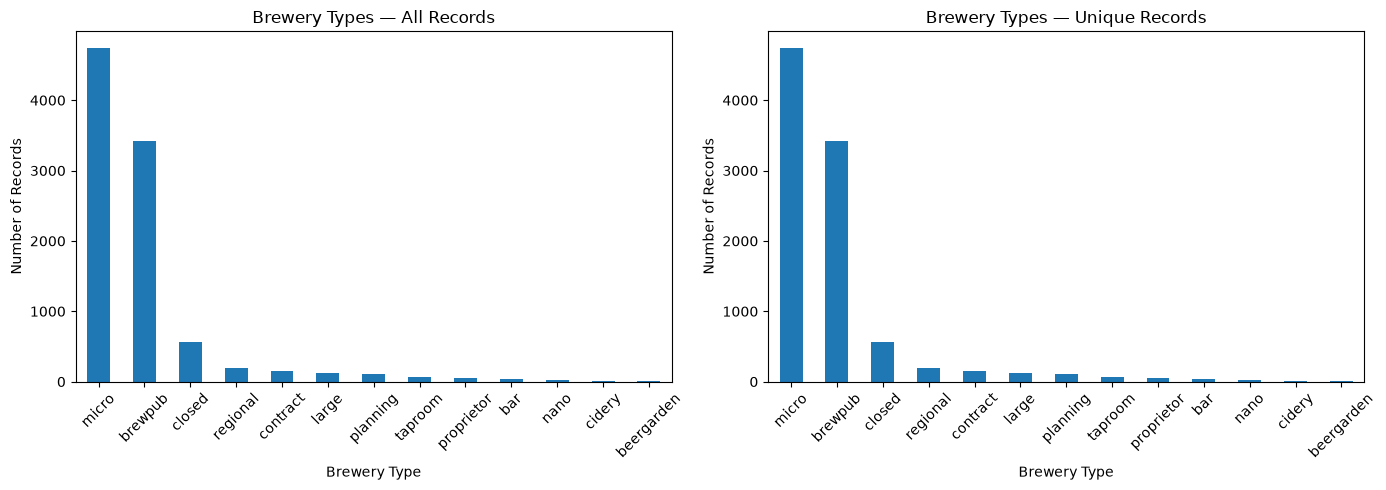

In [116]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

brewery_type_all.set_index('brewery_type')['record_count'].plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Brewery Types — All Records')
axes[0].set_xlabel('Brewery Type')
axes[0].set_ylabel('Number of Records')
axes[0].tick_params(axis='x', rotation=45)

brewery_type_unique.set_index('brewery_type')['record_count'].plot(
    kind='bar',
    ax=axes[1]
)

axes[1].set_title('Brewery Types — Unique Records')
axes[1].set_xlabel('Brewery Type')
axes[1].set_ylabel('Number of Records')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [117]:
brewery_type_all

,brewery_type,record_count,percentage
0,micro,4742,49.978921
1,brewpub,3417,36.013912
2,closed,560,5.902192
3,regional,201,2.118465
4,contract,145,1.528246
5,large,123,1.296374
6,planning,108,1.138280
7,taproom,64,0.674536
8,proprietor,47,0.495363
9,bar,44,0.463744


In [118]:
brewery_type_comparison

,all_records,unique_records,difference,all_records_percentage,unique_records_percentage
brewery_type,,,,,
bar,44,44,0,0.463744,0.463793
beergarden,6,6,0,0.063238,0.063244
brewpub,3417,3416,1,36.013912,36.007168
cidery,7,7,0,0.073777,0.073785
closed,560,560,0,5.902192,5.902814
contract,145,145,0,1.528246,1.528407
large,123,123,0,1.296374,1.296511
micro,4742,4742,0,49.978921,49.984189
nano,24,24,0,0.252951,0.252978


#### Top states

The left panel shows the top 25 state/province labels, the right panel only the top 15.

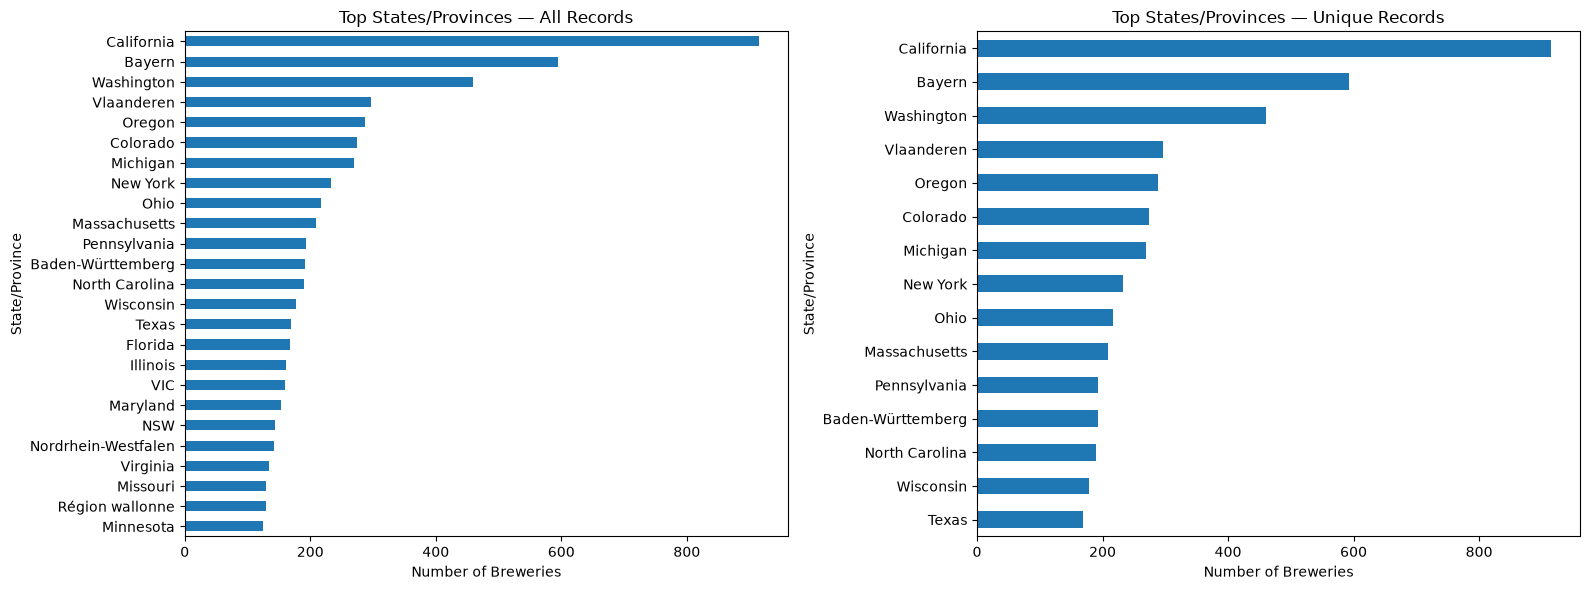

In [119]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

state_all.head(25).sort_values(
    'brewery_count'
).plot(
    x='state_province',
    y='brewery_count',
    kind='barh',
    ax=axes[0],
    legend=False
)

axes[0].set_title('Top States/Provinces — All Records')
axes[0].set_xlabel('Number of Breweries')
axes[0].set_ylabel('State/Province')

# The right panel shows only the top 15; the left panel shows the top 25.
state_unique.head(15).sort_values(
    'brewery_count'
).plot(
    x='state_province',
    y='brewery_count',
    kind='barh',
    ax=axes[1],
    legend=False
)

axes[1].set_title('Top States/Provinces — Unique Records')
axes[1].set_xlabel('Number of Breweries')
axes[1].set_ylabel('State/Province')

plt.tight_layout()
plt.show()

#### Top cities

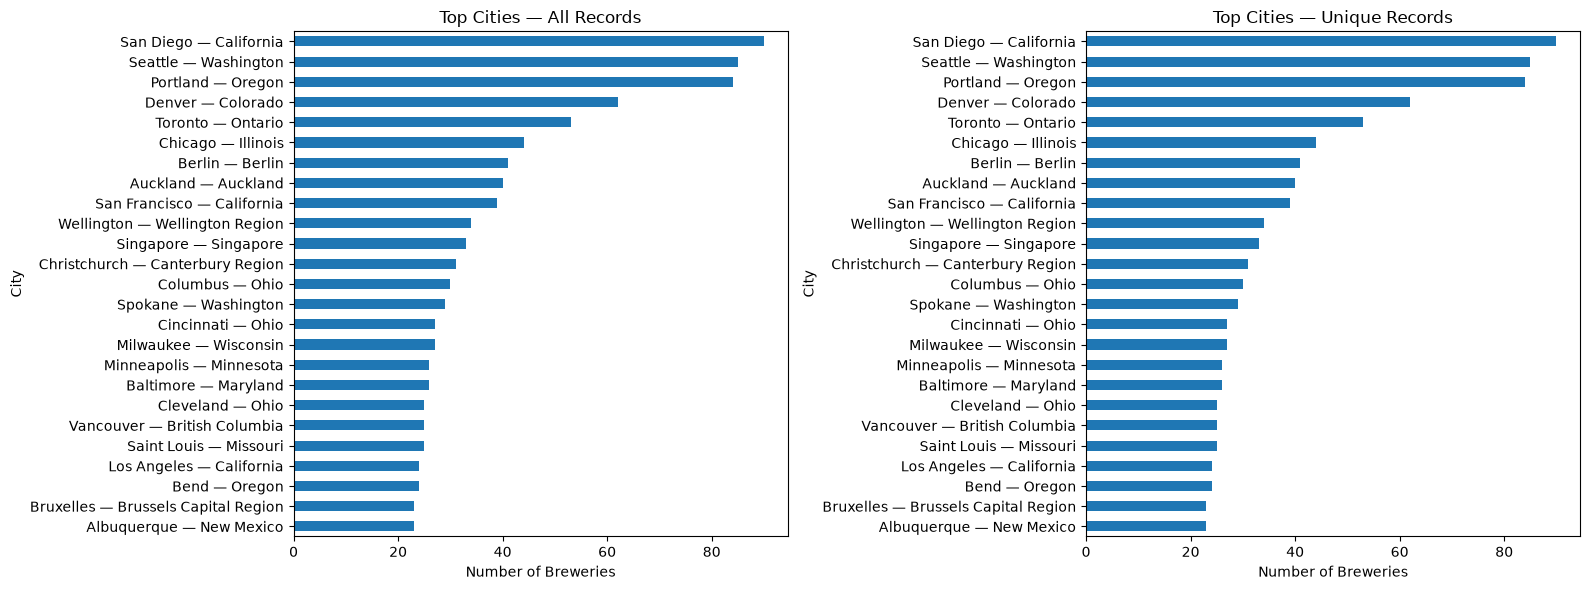

In [120]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

city_all.head(25).sort_values(
    'brewery_count'
).assign(
    city_state=lambda x:
    x['city'] + ' — ' + x['state_province']
).plot(
    x='city_state',
    y='brewery_count',
    kind='barh',
    ax=axes[0],
    legend=False
)

axes[0].set_title('Top Cities — All Records')
axes[0].set_xlabel('Number of Breweries')
axes[0].set_ylabel('City')

city_unique.head(25).sort_values(
    'brewery_count'
).assign(
    city_state=lambda x:
    x['city'] + ' — ' + x['state_province']
).plot(
    x='city_state',
    y='brewery_count',
    kind='barh',
    ax=axes[1],
    legend=False
)

axes[1].set_title('Top Cities — Unique Records')
axes[1].set_xlabel('Number of Breweries')
axes[1].set_ylabel('City')

plt.tight_layout()
plt.show()

### Geographic coordinate distribution

Histograms of the uncorrected coordinates for both datasets.

#### Longitude

Three groups: the Americas (negative longitudes, the largest group), Europe with South Africa around the prime meridian, and Australia, New Zealand and East Asia at the positive end.

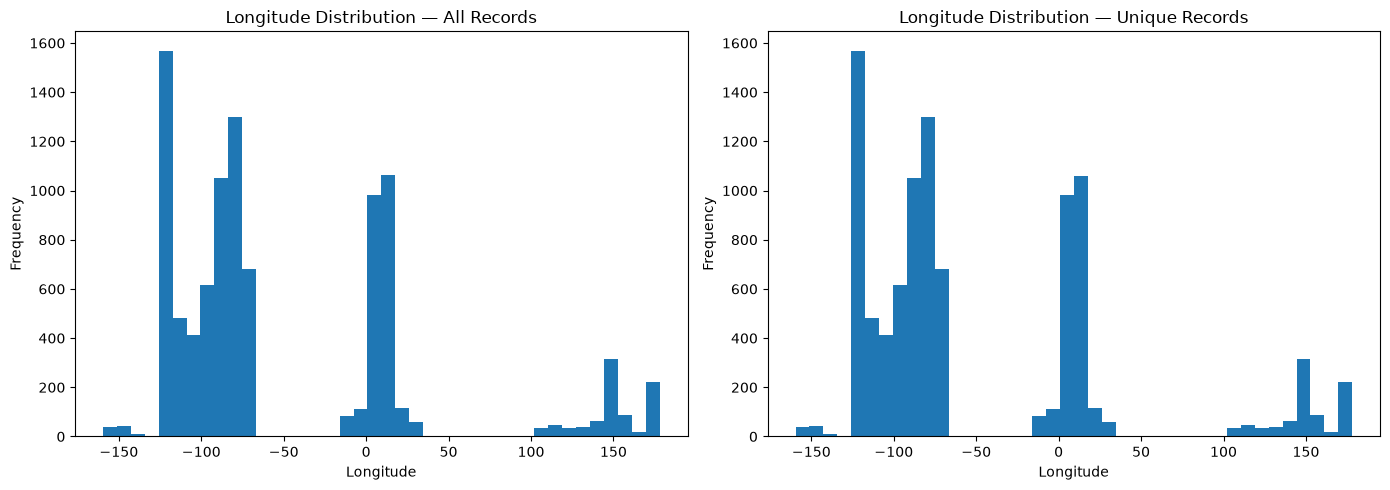

In [121]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

analysis_all_records['longitude'].plot(
    kind='hist',
    bins=40,
    ax=axes[0]
)

axes[0].set_title('Longitude Distribution — All Records')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Frequency')

analysis_unique_records['longitude'].plot(
    kind='hist',
    bins=40,
    ax=axes[1]
)

axes[1].set_title('Longitude Distribution — Unique Records')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

#### Latitude

Most records lie in the northern mid-latitudes (North America and Europe); the smaller southern group is Australia, New Zealand and South Africa. The axis stretches far south only because of the swapped Alabama record (minimum latitude -86.820901).

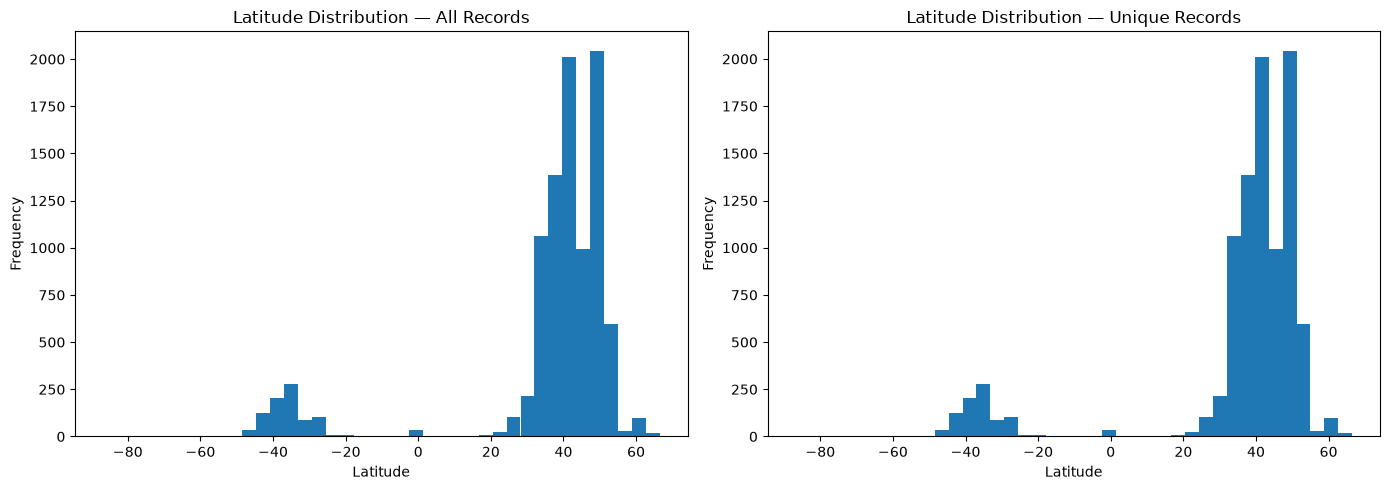

In [122]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

analysis_all_records['latitude'].plot(
    kind='hist',
    bins=40,
    ax=axes[0]
)

axes[0].set_title('Latitude Distribution — All Records')
axes[0].set_xlabel('Latitude')
axes[0].set_ylabel('Frequency')

analysis_unique_records['latitude'].plot(
    kind='hist',
    bins=40,
    ax=axes[1]
)

axes[1].set_title('Latitude Distribution — Unique Records')
axes[1].set_xlabel('Latitude')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Final comparison summary

The two datasets differ by one record and in nothing else at this level: same countries, state/province labels, cities and brewery types. Coordinate coverage is 100% in both by construction. The later notebooks and the dashboard still offer both datasets, so every result can be checked against the deduplicated version.

In [123]:
eda_summary = pd.DataFrame({
    'metric': [
        'Total records',
        'Countries',
        'States/Provinces',
        'Cities',
        'Brewery types',
        'Records with coordinates',
        'Coordinate coverage (%)'
    ],

    'all_records': [
        len(analysis_all_records),
        analysis_all_records['country'].nunique(),
        analysis_all_records['state_province'].nunique(),
        analysis_all_records['city'].nunique(),
        analysis_all_records['brewery_type'].nunique(),
        analysis_all_records[
            ['latitude', 'longitude']
        ].notna().all(axis=1).sum(),
        analysis_all_records[
            ['latitude', 'longitude']
        ].notna().all(axis=1).mean() * 100
    ],

    'unique_records': [
        len(analysis_unique_records),
        analysis_unique_records['country'].nunique(),
        analysis_unique_records['state_province'].nunique(),
        analysis_unique_records['city'].nunique(),
        analysis_unique_records['brewery_type'].nunique(),
        analysis_unique_records[
            ['latitude', 'longitude']
        ].notna().all(axis=1).sum(),
        analysis_unique_records[
            ['latitude', 'longitude']
        ].notna().all(axis=1).mean() * 100
    ]
})

eda_summary['difference'] = (
        eda_summary['all_records']
        - eda_summary['unique_records']
)

eda_summary

,metric,all_records,unique_records,difference
0,Total records,9488.0,9487.0,1.0
1,Countries,22.0,22.0,0.0
2,States/Provinces,211.0,211.0,0.0
3,Cities,4348.0,4348.0,0.0
4,Brewery types,13.0,13.0,0.0
5,Records with coordinates,9488.0,9487.0,1.0
6,Coordinate coverage (%),100.0,100.0,0.0


### City concentration within each state

Records per city next to the size of the city's state/province. Read `city_count` against `state_count`: the `city_share_of_state` column divides by the sum of `state_count` over all rows instead of by the city's own state, so it is not a share of the state. Berlin (41 of 41), Singapore (33 of 33) and Toronto (53 of 53) hold all of their region's geocoded records. For Toronto that is because most other Ontario records have no coordinates (section 9).

In [124]:
# ==========================================
# CITY CONCENTRATION WITHIN STATE
# ==========================================

city_state_summary = (
    analysis_all_records
    .groupby(
        ['country', 'state_province', 'city'],
        dropna=False
    )
    .size()
    .reset_index(name='city_count')
)

state_counts = (
    analysis_all_records
    .groupby(
        ['country', 'state_province'],
        dropna=False
    )
    .size()
    .reset_index(name='state_count')
)

city_state_summary = city_state_summary.merge(
    state_counts,
    on=['country', 'state_province'],
    how='left'
)

# Note: this divides by the sum of state_count over all rows, not by the city's own state_count,
# so the column is not a share of the state. Compare city_count with state_count instead.
city_state_summary['city_share_of_state'] = (
    city_state_summary['city_count']
    / city_state_summary['state_count'].sum()
    * 100
)

city_state_summary = city_state_summary.sort_values(
    'city_share_of_state',
    ascending=False
)

city_state_summary.head(20)

,country,state_province,city,city_count,state_count,city_share_of_state
2373,United States,California,San Diego,90,915,0.008340
4629,United States,Washington,Seattle,85,460,0.007877
4135,United States,Oregon,Portland,84,288,0.007784
2478,United States,Colorado,Denver,62,274,0.005746
613,Canada,Ontario,Toronto,53,53,0.004912
2770,United States,Illinois,Chicago,44,161,0.004078
1238,Germany,Berlin,Berlin,41,41,0.003800
1808,New Zealand,Auckland,Auckland,40,44,0.003707
2376,United States,California,San Francisco,39,915,0.003614
1873,New Zealand,Wellington Region,Wellington,34,42,0.003151


## 6. Geographic analysis: preparation

We make coordinate-complete copies of both datasets with `latitude_geo`/`longitude_geo` columns, so the geographic work does not change the datasets used above, and check coverage and value ranges once more. All 9488 and 9487 records keep their coordinates and none is out of range. The analysis itself (centers, distances, dispersion, outliers) continues in `brewery_geographic_analysis.ipynb`.

In [125]:
# Create independent geographic-analysis copies.
# Keeping these copies separate prevents geographic calculations from changing
# the original analysis datasets used by the earlier EDA sections.

# latitude_geo/longitude_geo are plain copies of the source columns; no swap is applied here.
geographic_datasets = {
    "all_records": analysis_all_records.copy(),
    "unique_records": analysis_unique_records.copy()
}

# The project established that the source coordinate fields need to be interpreted
# with this orientation for geographic calculations.
for dataset_name, df in geographic_datasets.items():
    df["latitude_geo"] = df["latitude"]
    df["longitude_geo"] = df["longitude"]

    # Keep only records with both coordinates available for spatial calculations.
    # We do not drop them from the original analysis datasets; we create a
    # coordinate-complete geographic view instead.
    geographic_datasets[dataset_name] = df.dropna(
        subset=["latitude_geo", "longitude_geo"]
    ).copy()

print("Geographic datasets created:")
for dataset_name, df in geographic_datasets.items():
    print(f"{dataset_name}: {df.shape[0]:,} coordinate-complete records")


Geographic datasets created:
all_records: 9,488 coordinate-complete records
unique_records: 9,487 coordinate-complete records


In [126]:
# Measure coordinate coverage for both analysis versions.

coverage_rows = []

for dataset_name, df in {
    "all_records": analysis_all_records,
    "unique_records": analysis_unique_records
}.items():

    total_records = len(df)

    latitude_present = df["latitude"].notna()
    longitude_present = df["longitude"].notna()
    both_coordinates_present = latitude_present & longitude_present

    coverage_rows.append({
        "dataset": dataset_name,
        "total_records": total_records,
        "latitude_present": latitude_present.sum(),
        "longitude_present": longitude_present.sum(),
        "both_coordinates_present": both_coordinates_present.sum(),
        "records_missing_latitude": (~latitude_present).sum(),
        "records_missing_longitude": (~longitude_present).sum(),
        "records_missing_either_coordinate": (~both_coordinates_present).sum(),
        "record_coordinate_coverage_pct": (
            both_coordinates_present.mean() * 100
            if total_records > 0 else np.nan
        ),
        "latitude_coverage_pct": (
            latitude_present.mean() * 100
            if total_records > 0 else np.nan
        ),
        "longitude_coverage_pct": (
            longitude_present.mean() * 100
            if total_records > 0 else np.nan
        )
    })

coordinate_coverage = pd.DataFrame(coverage_rows)

coordinate_coverage


,dataset,total_records,latitude_present,longitude_present,both_coordinates_present,records_missing_latitude,records_missing_longitude,records_missing_either_coordinate,record_coordinate_coverage_pct,latitude_coverage_pct,longitude_coverage_pct
0,all_records,9488,9488,9488,9488,0,0,0,100.0,100.0,100.0
1,unique_records,9487,9487,9487,9487,0,0,0,100.0,100.0,100.0


In [127]:
# Check coordinate ranges after applying the project's geographic interpretation.
# This is a validation step before calculating distances or geographic centers.

coordinate_range_checks = []

for dataset_name, df in geographic_datasets.items():
    # print(dataset_name, df.columns)
    coordinate_range_checks.append({
        "dataset": dataset_name,
        "records": len(df),
        "latitude_min": df["latitude_geo"].min(),
        "latitude_max": df["latitude_geo"].max(),
        "longitude_min": df["longitude_geo"].min(),
        "longitude_max": df["longitude_geo"].max(),
        "invalid_latitude": (~df["latitude_geo"].between(-90, 90)).sum(),
        "invalid_longitude": (~df["longitude_geo"].between(-180, 180)).sum()
    })

coordinate_range_checks = pd.DataFrame(coordinate_range_checks)
coordinate_range_checks


,dataset,records,latitude_min,latitude_max,longitude_min,longitude_max,invalid_latitude,invalid_longitude
0,all_records,9488,-86.820901,66.4914,-159.586522,178.017207,0,0
1,unique_records,9487,-86.820901,66.4914,-159.586522,178.017207,0,0


In [128]:
coordinate_range_checks.columns

Index(['dataset', 'records', 'latitude_min', 'latitude_max', 'longitude_min',
       'longitude_max', 'invalid_latitude', 'invalid_longitude'],
      dtype='str')

In [129]:
coordinate_range_checks['invalid_latitude']

0    0
1    0
Name: invalid_latitude, dtype: int64

In [130]:
# Leftover spot check by position (iloc); not used later.
# ********
analysis_unique_records.iloc[8131]

id                6b076ecd-c79f-41b2-a5c6-e19faa9cf8aa
name                             SwitchGear Brewing Co
brewery_type                                     micro
address_1                            44 D Gottfried St
address_2                                          NaN
address_3                                          NaN
city                                      Elkhart Lake
state_province                               Wisconsin
postal_code                                      53020
country                                  United States
longitude                                   -88.019601
latitude                                     43.834243
phone                                       9207815120
website_url           http://www.switchgearbrewing.com
state                                        Wisconsin
street                               44 D Gottfried St
Name: 10215, dtype: object

In [131]:
# # Check coordinate ranges after applying the project's geographic interpretation.
# # This is a validation step before calculating distances or geographic centers.
#
# coordinate_range_checks = []
# invalid_coordinate_records = {}
#
# for dataset_name, df in geographic_datasets.items():
#
#     # Identify records with invalid latitude OR invalid longitude
#     invalid_mask = (
#         ~df["latitude_geo"].between(-90, 90) |
#         ~df["longitude_geo"].between(-180, 180)
#     )
#
#     # Keep all columns for invalid records
#     invalid_coordinate_records[dataset_name] = df.loc[invalid_mask].copy()
#
#     # Summary statistics
#     coordinate_range_checks.append({
#         "dataset": dataset_name,
#         "records": len(df),
#         "latitude_min": df["latitude_geo"].min(),
#         "latitude_max": df["latitude_geo"].max(),
#         "longitude_min": df["longitude_geo"].min(),
#         "longitude_max": df["longitude_geo"].max(),
#         "invalid_latitude": (~df["latitude_geo"].between(-90, 90)).sum(),
#         "invalid_longitude": (~df["longitude_geo"].between(-180, 180)).sum(),
#         "invalid_coordinates": invalid_mask.sum()
#     })
#
# coordinate_range_checks = pd.DataFrame(coordinate_range_checks)
#
# # coordinate_range_checks
# pd.DataFrame(invalid_coordinate_records)

In [132]:
# invalid_coordinate_records_df = pd.concat(
#     invalid_coordinate_records,
#     names=["dataset"]
# ).reset_index(level="dataset")
#
# invalid_coordinate_records_df

## 7. Saving the analysis datasets

We write both datasets to `data/analysis_all_records.db` and `data/analysis_unique_records.db`, the files the later notebooks and the dashboard read. They are written before `state` is dropped in section 10, so the saved tables still contain it.

In [133]:
#   @: Creates a SQLite SQLAlchemy database_engine and writes the brewery DataFrame to the `breweries` table, replacing an existing table.

# Saves analysis_all_records to data/analysis_all_records.db, read by the later notebooks and the dashboard.
from sqlalchemy import create_engine

database_engine = create_engine('sqlite:///data/analysis_all_records.db')

analysis_all_records.to_sql(
    'analysis_all_records',
    con=database_engine,
    if_exists='replace',
    index=False
)

9488

In [134]:
#   @: Creates a SQLite SQLAlchemy database_engine and writes the brewery DataFrame to the `breweries` table, replacing an existing table.

# Saves analysis_unique_records to data/analysis_unique_records.db.
from sqlalchemy import create_engine

database_engine = create_engine('sqlite:///data/analysis_unique_records.db')

analysis_unique_records.to_sql(
    'analysis_unique_records',
    con=database_engine,
    if_exists='replace',
    index=False
)

9487

## 8. Swapped-coordinate check

A record with latitude and longitude exchanged shows up here only if the stored latitude falls outside the valid range. None does, in either dataset. The check cannot catch a swap when both values are valid latitudes, and that is the case for all the swapped records we found later by comparing each brewery with the center of the city it names. The dashboard corrects those records.

In [135]:
# Swap candidates: latitude out of range while the longitude would be a valid latitude.
invalid_lat_mask = ~analysis_unique_records["latitude"].between(-90, 90)

swap_candidates = analysis_unique_records.loc[
    invalid_lat_mask &
    analysis_unique_records["longitude"].between(-90, 90)
].copy()

len(swap_candidates)

0

In [136]:
invalid_lat_mask = ~analysis_all_records["latitude"].between(-90, 90)

swap_candidates = analysis_all_records.loc[
    invalid_lat_mask &
    analysis_all_records["longitude"].between(-90, 90)
].copy()

len(swap_candidates)

0

## 9. Missing coordinates in the raw snapshot

The analysis datasets have no missing coordinates, so this section goes back to the raw snapshot, where 2468 of 11959 records have neither latitude nor longitude. The first tables show how those 2468 records split by type, state, country and city (shares of the missing records). The second set shows the missing rate within each group, which is the fairer comparison.

The gaps are not random:
- by type, 526 of 634 `planning` breweries have no coordinates, against 1171 of 5916 `micro` breweries;
- by country, Sweden misses 30 of 36, Canada 111 of 283 and the United States 2297 of 8334, while Australia, Belgium and New Zealand miss none;
- by state, Stockholm County misses all 26, Ontario 111 of 164 and Vermont 29 of 52.

Every geographic result in the project therefore describes geocoded breweries, not all breweries. The dashboard shows this in the Missing Coordinates tab of `app.py` and on `pages/1_Data_Quality.py`.

In [137]:

# ============================================================
# 1. MISSING-COORDINATE ANALYSIS
# Run before dropping rows with missing coordinates.
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# Keep the source unchanged.
missing_coord_source = raw_breweries_df.copy()

# Ensure coordinates are numeric.
for col in ["latitude", "longitude"]:
    missing_coord_source[col] = pd.to_numeric(
        missing_coord_source[col], errors="coerce"
    )

lat_missing = missing_coord_source["latitude"].isna()
lon_missing = missing_coord_source["longitude"].isna()

missing_coord_source["coordinate_status"] = np.select(
    [
        lat_missing & lon_missing,
        lat_missing & ~lon_missing,
        ~lat_missing & lon_missing,
    ],
    [
        "Both missing",
        "Latitude missing only",
        "Longitude missing only",
    ],
    default="Both available",
)

# Records requiring investigation.
missing_coordinates_df = missing_coord_source.loc[
    missing_coord_source["coordinate_status"] != "Both available"
].copy()

print("Total source records:", len(missing_coord_source))
print("Records with both coordinates missing:", (lat_missing & lon_missing).sum())
print("Records with latitude missing only:", (lat_missing & ~lon_missing).sum())
print("Records with longitude missing only:", (~lat_missing & lon_missing).sum())
print("Records with at least one coordinate missing:", len(missing_coordinates_df))

display(
    missing_coordinates_df[
        [
            "id", "name", "brewery_type", "city",
            "state", "state_province", "country",
            "latitude", "longitude", "coordinate_status",
        ]
    ].head(30)
)


Total source records: 11959
Records with both coordinates missing: 2468
Records with latitude missing only: 0
Records with longitude missing only: 0
Records with at least one coordinate missing: 2468


,id,name,brewery_type,city,state,state_province,country,latitude,longitude,coordinate_status
4,9c5a66c8-cc13-416f-a5d9-0a769c87d318,(512) Brewing Co,micro,Austin,Texas,Texas,United States,NaN,NaN,Both missing
24,d81ff708-b5d2-478f-af6a-6d40f5beb9ac,12 Gates Brewing Company,brewpub,Williamsville,New York,New York,United States,NaN,NaN,Both missing
25,f4284868-386f-46c2-adda-0436d6a9e3bd,12 Marias,micro,Estarreja,Aveiro,Aveiro,Portugal,NaN,NaN,Both missing
26,fb94830f-6196-4f59-9189-c9060b778085,12 West Brewing Company,micro,Gilbert,Arizona,Arizona,United States,NaN,NaN,Both missing
31,50521ef7-f543-4c5d-98b1-0d0ee1a2be01,12welve Eyes Brewing,micro,Saint Paul,Minnesota,Minnesota,United States,NaN,NaN,Both missing
33,45119c56-345b-4adc-b481-c5cf7bfe98c4,13 Stripes Brewery,brewpub,Taylors,South Carolina,South Carolina,United States,NaN,NaN,Both missing
35,5c53b314-ebab-4e3e-89be-e4139d9318ae,1323 R & D,micro,Raleigh,North Carolina,North Carolina,United States,NaN,NaN,Both missing
36,19ff5276-c1b2-423a-b6ac-ae47f97efc96,137:ans,micro,Södertälje,Stockholm County,Stockholm County,Sweden,NaN,NaN,Both missing
38,b7b68d22-5045-4501-b9bf-ec94946eaffc,14 Lakes Brewery,micro,Crosslake,Minnesota,Minnesota,United States,NaN,NaN,Both missing
40,6c53984f-fac1-4ea7-9c44-44e25897c71a,14th Star Brewing,micro,Saint Albans,Vermont,Vermont,United States,NaN,NaN,Both missing


In [138]:

# ============================================================
# 2. MISSING COORDINATES BY CATEGORY
# ============================================================

def summarize_missing_coordinates(df, column):
    summary = (
        df.assign(
            category=df[column].astype("string").fillna("(Missing)")
        )
        .groupby("category", dropna=False)
        .size()
        .rename("record_count")
        .reset_index()
        .rename(columns={"category": column})
        .sort_values("record_count", ascending=False)
        .reset_index(drop=True)
    )

    denominator = len(df)

    summary["percentage_of_missing_coordinate_records"] = (
        summary["record_count"] / denominator * 100
        if denominator else 0
    )

    return summary


# Shares here are of the 2468 records without coordinates, not of each group;
# the rate within each group follows in part 3.
missing_by_brewery_type = summarize_missing_coordinates(
    missing_coordinates_df, "brewery_type"
)

missing_by_state = summarize_missing_coordinates(
    missing_coordinates_df, "state_province"
)

missing_by_country = summarize_missing_coordinates(
    missing_coordinates_df, "country"
)

missing_by_city = summarize_missing_coordinates(
    missing_coordinates_df, "city"
)

print("Missing coordinates by brewery type")
display(missing_by_brewery_type)

print("Missing coordinates by state/province")
display(missing_by_state)

print("Missing coordinates by country")
display(missing_by_country)

print("Missing coordinates by city")
display(missing_by_city)


Missing coordinates by brewery type


,brewery_type,record_count,percentage_of_missing_coordinate_records
0,micro,1171,47.447326
1,brewpub,533,21.596434
2,planning,526,21.312804
3,closed,85,3.444084
4,contract,74,2.998379
5,regional,39,1.580227
6,proprietor,20,0.810373
7,large,14,0.567261
8,nano,4,0.162075
9,bar,1,0.040519


Missing coordinates by state/province


,state_province,record_count,percentage_of_missing_coordinate_records
0,New York,186,7.536467
1,Texas,183,7.414911
2,Colorado,176,7.131280
3,Pennsylvania,152,6.158833
4,Florida,146,5.915721
...,...,...,...
62,North Dakota,1,0.040519
63,Niedersachsen,1,0.040519
64,South Dakota,1,0.040519
65,Rheinland-Pfalz,1,0.040519


Missing coordinates by country


,country,record_count,percentage_of_missing_coordinate_records
0,United States,2297,93.071313
1,Canada,111,4.497569
2,Sweden,30,1.215559
3,Portugal,15,0.607780
4,Germany,13,0.526742
5,South Korea,1,0.040519
6,Ukraine,1,0.040519


Missing coordinates by city


,city,record_count,percentage_of_missing_coordinate_records
0,Denver,30,1.215559
1,Austin,26,1.053485
2,Houston,22,0.891410
3,Chicago,20,0.810373
4,Indianapolis,16,0.648298
...,...,...,...
1388,Winthrop,1,0.040519
1389,Winter Springs,1,0.040519
1390,Winston-Salem,1,0.040519
1391,Wingham,1,0.040519


In [139]:
missing_by_brewery_type

,brewery_type,record_count,percentage_of_missing_coordinate_records
0,micro,1171,47.447326
1,brewpub,533,21.596434
2,planning,526,21.312804
3,closed,85,3.444084
4,contract,74,2.998379
5,regional,39,1.580227
6,proprietor,20,0.810373
7,large,14,0.567261
8,nano,4,0.162075
9,bar,1,0.040519


In [140]:
missing_by_state

,state_province,record_count,percentage_of_missing_coordinate_records
0,New York,186,7.536467
1,Texas,183,7.414911
2,Colorado,176,7.131280
3,Pennsylvania,152,6.158833
4,Florida,146,5.915721
...,...,...,...
62,North Dakota,1,0.040519
63,Niedersachsen,1,0.040519
64,South Dakota,1,0.040519
65,Rheinland-Pfalz,1,0.040519


In [141]:
missing_by_country

,country,record_count,percentage_of_missing_coordinate_records
0,United States,2297,93.071313
1,Canada,111,4.497569
2,Sweden,30,1.215559
3,Portugal,15,0.607780
4,Germany,13,0.526742
5,South Korea,1,0.040519
6,Ukraine,1,0.040519


In [142]:
missing_by_city

,city,record_count,percentage_of_missing_coordinate_records
0,Denver,30,1.215559
1,Austin,26,1.053485
2,Houston,22,0.891410
3,Chicago,20,0.810373
4,Indianapolis,16,0.648298
...,...,...,...
1388,Winthrop,1,0.040519
1389,Winter Springs,1,0.040519
1390,Winston-Salem,1,0.040519
1391,Wingham,1,0.040519


In [143]:

# ============================================================
# 3. MISSING-COORDINATE RATE WITHIN EACH CATEGORY
# ============================================================

def coordinate_missing_rate(df, column):
    work = df.copy()
    work[column] = work[column].astype("string").fillna("(Missing)")

    work["has_missing_coordinates"] = (
        work["latitude"].isna() | work["longitude"].isna()
    )

    result = (
        work.groupby(column, dropna=False)
        .agg(
            total_records=("id", "size"),
            records_missing_coordinates=("has_missing_coordinates", "sum"),
        )
        .reset_index()
    )

    result["missing_coordinate_percentage"] = (
        result["records_missing_coordinates"]
        / result["total_records"]
        * 100
    )

    return result.sort_values(
        ["missing_coordinate_percentage", "total_records"],
        ascending=[False, False],
    ).reset_index(drop=True)


missing_rate_by_type = coordinate_missing_rate(
    missing_coord_source, "brewery_type"
)

missing_rate_by_state = coordinate_missing_rate(
    missing_coord_source, "state_province"
)

missing_rate_by_country = coordinate_missing_rate(
    missing_coord_source, "country"
)

missing_rate_by_city = coordinate_missing_rate(
    missing_coord_source, "city"
)

display(missing_rate_by_type)
display(missing_rate_by_state)
display(missing_rate_by_country)
display(missing_rate_by_city)


,brewery_type,total_records,records_missing_coordinates,missing_coordinate_percentage
0,planning,634,526,82.965300
1,contract,219,74,33.789954
2,proprietor,67,20,29.850746
3,micro,5916,1171,19.793780
4,regional,240,39,16.250000
5,nano,28,4,14.285714
6,brewpub,3950,533,13.493671
7,closed,645,85,13.178295
8,large,137,14,10.218978
9,bar,45,1,2.222222


,state_province,total_records,records_missing_coordinates,missing_coordinate_percentage
0,Stockholm County,26,26,100.000000
1,Halland,4,4,100.000000
2,Dnipropetrovsk Oblast,1,1,100.000000
3,Ontario,164,111,67.682927
4,Vermont,52,29,55.769231
...,...,...,...,...
209,Salzburg,1,0,0.000000
210,South Karelia,1,0,0.000000
211,Vila Real,1,0,0.000000
212,Westmeath,1,0,0.000000


,country,total_records,records_missing_coordinates,missing_coordinate_percentage
0,Ukraine,1,1,100.000000
1,Sweden,36,30,83.333333
2,Canada,283,111,39.222615
3,United States,8334,2297,27.561795
4,Portugal,72,15,20.833333
5,South Korea,62,1,1.612903
6,Germany,1445,13,0.899654
7,Australia,514,0,0.000000
8,Belgium,478,0,0.000000
9,New Zealand,243,0,0.000000


,city,total_records,records_missing_coordinates,missing_coordinate_percentage
0,Stockholm,6,6,100.0
1,Clearwater,5,5,100.0
2,London,5,5,100.0
3,Bay Shore,4,4,100.0
4,Cedar Park,4,4,100.0
...,...,...,...,...
5060,salt lake city,1,0,0.0
5061,Érezée,1,0,0.0
5062,Łomnica,1,0,0.0
5063,Świdnica,1,0,0.0


In [144]:
missing_rate_by_type

,brewery_type,total_records,records_missing_coordinates,missing_coordinate_percentage
0,planning,634,526,82.965300
1,contract,219,74,33.789954
2,proprietor,67,20,29.850746
3,micro,5916,1171,19.793780
4,regional,240,39,16.250000
5,nano,28,4,14.285714
6,brewpub,3950,533,13.493671
7,closed,645,85,13.178295
8,large,137,14,10.218978
9,bar,45,1,2.222222


In [145]:
missing_rate_by_state

,state_province,total_records,records_missing_coordinates,missing_coordinate_percentage
0,Stockholm County,26,26,100.000000
1,Halland,4,4,100.000000
2,Dnipropetrovsk Oblast,1,1,100.000000
3,Ontario,164,111,67.682927
4,Vermont,52,29,55.769231
...,...,...,...,...
209,Salzburg,1,0,0.000000
210,South Karelia,1,0,0.000000
211,Vila Real,1,0,0.000000
212,Westmeath,1,0,0.000000


In [146]:
missing_rate_by_country

,country,total_records,records_missing_coordinates,missing_coordinate_percentage
0,Ukraine,1,1,100.000000
1,Sweden,36,30,83.333333
2,Canada,283,111,39.222615
3,United States,8334,2297,27.561795
4,Portugal,72,15,20.833333
5,South Korea,62,1,1.612903
6,Germany,1445,13,0.899654
7,Australia,514,0,0.000000
8,Belgium,478,0,0.000000
9,New Zealand,243,0,0.000000


In [147]:
missing_rate_by_city

,city,total_records,records_missing_coordinates,missing_coordinate_percentage
0,Stockholm,6,6,100.0
1,Clearwater,5,5,100.0
2,London,5,5,100.0
3,Bay Shore,4,4,100.0
4,Cedar Park,4,4,100.0
...,...,...,...,...
5060,salt lake city,1,0,0.0
5061,Érezée,1,0,0.0
5062,Łomnica,1,0,0.0
5063,Świdnica,1,0,0.0


## 10. `state` vs `state_province`

After trimming whitespace and ignoring case, `state` equals `state_province` in all 11959 raw records, so `state` adds nothing. The next cell drops it from the in-memory DataFrames; the saved databases keep it. Identical columns do not mean clean labels: the same region can still appear under several labels (Belgian regions in three languages, a `MIssouri` typo in the US), which the dashboard harmonizes into `state_province_harmonized`.

In [148]:

# ============================================================
# 4. COMPARE state AND state_province
# ============================================================

state_check_df = raw_breweries_df[
    ["id", "name", "country", "city", "state", "state_province"]
].copy()

def normalize_state(series):
    return (
        series.astype("string")
        .str.strip()
        .str.casefold()
        .replace("", pd.NA)
    )

state_normalized = normalize_state(state_check_df["state"])
province_normalized = normalize_state(state_check_df["state_province"])

both_missing = state_normalized.isna() & province_normalized.isna()
one_missing = state_normalized.isna() ^ province_normalized.isna()

both_present = state_normalized.notna() & province_normalized.notna()

different_values = (
    both_present & state_normalized.ne(province_normalized)
)

state_check_df["comparison_result"] = np.select(
    [
        both_missing,
        one_missing,
        different_values,
    ],
    [
        "Both missing",
        "Only one missing",
        "Different values",
    ],
    default="Equivalent values",
)

display(
    state_check_df["comparison_result"]
    .value_counts(dropna=False)
    .rename_axis("comparison_result")
    .reset_index(name="record_count")
)

state_discrepancies = state_check_df[
    state_check_df["comparison_result"].isin(
        ["Only one missing", "Different values"]
    )
].copy()

display(state_discrepancies)


,comparison_result,record_count
0,Equivalent values,11959


,id,name,country,city,state,state_province,comparison_result


In [149]:

# ============================================================
# 5. DROP state ONLY IF IT IS REDUNDANT
# ============================================================

state_is_redundant = (
    not one_missing.any()
    and not different_values.any()
)

if state_is_redundant:
    print(
        "state and state_province are equivalent. "
        "Keeping state_province and dropping state."
    )

    # Apply to your in-memory analysis datasets.
    # Drops `state` in memory only; the databases saved in section 7 keep it.
    for df_name in [
        "raw_breweries_df",
        "analysis_all_records",
        "analysis_unique_records",
    ]:
        if df_name in globals():
            df = globals()[df_name]
            if "state" in df.columns:
                globals()[df_name] = df.drop(columns="state")

else:
    print(
        "Do not drop state yet. "
        "Inspect state_discrepancies before deciding."
    )


state and state_province are equivalent. Keeping state_province and dropping state.


## 11. Latitude and longitude distribution (interactive)

Plotly maps colored by latitude and by longitude, and histograms with box plots, for all 9488 records with their uncorrected coordinates. The figures are stored as Plotly output, which GitHub does not render; run the notebook locally or open `pages/3_Lat_Lon_Distribution.py` in the dashboard.

In [150]:

# ============================================================
# 6. LATITUDE AND LONGITUDE DISTRIBUTION VISUALIZATIONS
# ============================================================

import plotly.express as px
from IPython.display import display

# Choose which analysis dataset to visualize.
# Change to analysis_unique_records for unique-location analysis.
# Coordinates are uncorrected here, so the swapped records still plot in the wrong place.
coordinate_plot_df = analysis_all_records.copy()

coordinate_plot_df[("latitude")] = pd.to_numeric(
    coordinate_plot_df["latitude"], errors="coerce"
)
coordinate_plot_df["longitude"] = pd.to_numeric(
    coordinate_plot_df["longitude"], errors="coerce"
)

# Keep only valid geographic coordinate pairs.
coordinate_plot_df = coordinate_plot_df[
    coordinate_plot_df["latitude"].between(-90, 90)
    & coordinate_plot_df["longitude"].between(-180, 180)
].copy()

print("Records included in coordinate distributions:", len(coordinate_plot_df))

# ------------------------------------------------------------
# A. MAPS: LATITUDE AND LONGITUDE
# ------------------------------------------------------------

# Unused leftover line.
left, right = __import__("plotly").graph_objects, None

fig_latitude_map = px.scatter_geo(
    coordinate_plot_df,
    lat="latitude",
    lon="longitude",
    color="latitude",
    hover_name="name" if "name" in coordinate_plot_df.columns else None,
    hover_data={
        "latitude": ":.5f",
        "longitude": ":.5f",
        "city": True if "city" in coordinate_plot_df.columns else False,
        "state_province": True if "state_province" in coordinate_plot_df.columns else False,
        "country": True if "country" in coordinate_plot_df.columns else False,
    },
    color_continuous_scale="Viridis",
    title="Geographic distribution of latitude values",
    projection="natural earth",
)

fig_latitude_map.update_layout(
    geo=dict(showland=True, showcountries=True),
    coloraxis_colorbar_title="Latitude (°)",
    margin=dict(l=0, r=0, t=55, b=0),
)

fig_longitude_map = px.scatter_geo(
    coordinate_plot_df,
    lat="latitude",
    lon="longitude",
    color="longitude",
    hover_name="name" if "name" in coordinate_plot_df.columns else None,
    hover_data={
        "latitude": ":.5f",
        "longitude": ":.5f",
        "city": True if "city" in coordinate_plot_df.columns else False,
        "state_province": True if "state_province" in coordinate_plot_df.columns else False,
        "country": True if "country" in coordinate_plot_df.columns else False,
    },
    color_continuous_scale="Plasma",
    title="Geographic distribution of longitude values",
    projection="natural earth",
)

fig_longitude_map.update_layout(
    geo=dict(showland=True, showcountries=True),
    coloraxis_colorbar_title="Longitude (°)",
    margin=dict(l=0, r=0, t=55, b=0),
)

fig_latitude_map.show()
fig_longitude_map.show()

# ------------------------------------------------------------
# B. STATISTICAL DISTRIBUTIONS
# ------------------------------------------------------------

fig_latitude_dist = px.histogram(
    coordinate_plot_df,
    x="latitude",
    nbins=50,
    marginal="box",
    title="Distribution of latitude values",
    labels={"latitude": "Latitude (degrees)", "count": "Record count"},
)

fig_latitude_dist.update_layout(
    xaxis_title="Latitude (degrees)",
    yaxis_title="Number of records",
)

fig_longitude_dist = px.histogram(
    coordinate_plot_df,
    x="longitude",
    nbins=50,
    marginal="box",
    title="Distribution of longitude values",
    labels={"longitude": "Longitude (degrees)", "count": "Record count"},
)

fig_longitude_dist.update_layout(
    xaxis_title="Longitude (degrees)",
    yaxis_title="Number of records",
)

fig_latitude_dist.show()
fig_longitude_dist.show()


Records included in coordinate distributions: 9488


### Re-running the `state` comparison

This cell repeats the comparison without changing any DataFrame. In the stored run it reports that `state` is missing, because the drop in section 10 had already run. The result above stands.

In [151]:
# In the stored run this prints a message instead of a result: `state` had already been dropped
# by the step in section 10.
import pandas as pd

# 1. Check that both columns exist
required_columns = {"state", "state_province"}
missing_columns = required_columns - set(raw_breweries_df.columns)

if missing_columns:
    print("Cannot compare. Missing columns:", missing_columns)

else:
    # 2. Make temporary normalized copies for comparison.
    # This does NOT change raw_breweries_df.
    state = (
        raw_breweries_df["state"]
        .astype("string")
        .str.strip()
        .str.casefold()
        .replace("", pd.NA)
    )

    state_province = (
        raw_breweries_df["state_province"]
        .astype("string")
        .str.strip()
        .str.casefold()
        .replace("", pd.NA)
    )

    # 3. Categorize the comparison results
    both_missing = state.isna() & state_province.isna()
    only_state_missing = state.isna() & state_province.notna()
    only_state_province_missing = state.notna() & state_province.isna()
    both_present_same = (
        state.notna()
        & state_province.notna()
        & state.eq(state_province)
    )
    both_present_different = (
        state.notna()
        & state_province.notna()
        & state.ne(state_province)
    )

    # 4. Summarize the results
    comparison_summary = pd.DataFrame({
        "comparison": [
            "Both values missing",
            "Only state is missing",
            "Only state_province is missing",
            "Both present and equal",
            "Both present but different",
        ],
        "record_count": [
            both_missing.sum(),
            only_state_missing.sum(),
            only_state_province_missing.sum(),
            both_present_same.sum(),
            both_present_different.sum(),
        ],
    })

    comparison_summary["percentage"] = (
        comparison_summary["record_count"]
        / len(raw_breweries_df) * 100
    ).round(2)

    display(comparison_summary)

    # 5. Display rows where the columns do not match
    mismatch_mask = (
        only_state_missing
        | only_state_province_missing
        | both_present_different
    )

    mismatch_columns = [
        col for col in [
            "id", "name", "city", "country",
            "state", "state_province"
        ]
        if col in raw_breweries_df.columns
    ]

    print("Rows where the columns differ or only one is missing:")
    display(raw_breweries_df.loc[mismatch_mask, mismatch_columns])

    # 6. Give a conclusion without changing any DataFrame
    state_is_redundant = (
        only_state_missing.sum() == 0
        and only_state_province_missing.sum() == 0
        and both_present_different.sum() == 0
    )

    if state_is_redundant:
        print(
            "\nConclusion: The columns are equivalent for all records "
            "after normalizing capitalization and whitespace. "
            "'state' appears redundant."
        )
    else:
        print(
            "\nConclusion: The columns are not fully equivalent. "
            "Review the mismatch rows before deciding whether "
            "to drop either column."
        )

Cannot compare. Missing columns: {'state'}


In [152]:
#